# Grosmark & Buzsáki (2016) — behavior on the 1.6 m linear track

Comparison dataset for the bat digital-twin work. CRCNS **hc-11**: bilateral CA1 silicon-probe
recordings in 4 male Long-Evans rats, each session = PRE sleep (~4 h) → novel MAZE running (~45 min)
→ POST sleep (~4 h).

We restrict to the **four 1.6 m linear-track sessions** (one per rat):

| Session | Rat | MAZE dur | Pyr cells |
|---|---|---|---|
| `Buddy_06272013` | Buddy | 2328 s | 48 |
| `Gatsby_08022013` | Gatsby | 2335 s | 66 |
| `Achilles_10252013` | Achilles | 2068 s | 120 |
| `Cicero_09012014` | Cicero | 5561 s | 55 |

**Goal of this notebook (step 1): just visualize the behavior.** Can the linear-track running be
segmented into leftward / rightward runs? Following Grosmark & Buzsáki, place-field analysis is
restricted to *"epochs during which the animal's velocity was at least 5 cm/s and in which the rat
was outside of the reward areas."*

**Data layout** (per `*_sessInfo.mat`, HDF5 / `-v7.3`):
- `Position.OneDLocation` — 1-D linearization of track position, **in meters, 0 → 1.6**. This is the
  linearized *stem* length already reported in the paper (i.e. the 15 cm reward areas at each end
  are excluded), and is `NaN` whenever the rat is off the linear track / in a tracking gap.
- `Position.TwoDLocation` — 2-D position (m).
- `Position.TimeStamps` — ~39 Hz, in seconds; offset into the concatenated session (starts at the
  MAZE epoch, not 0).
- `Epochs.MazeEpoch` — `[start, end]` of the running epoch in seconds.

In [46]:
import os
import h5py
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

sns.set_context('notebook')
sns.set_style('ticks')

DATA_DIR = '/media/alowet/ssd2/grosmark/data/NoveltySessInfoMatFiles'

# The four 1.6 m linear-track sessions (one session per rat)
SESSIONS = ['Buddy_06272013', 'Gatsby_08022013', 'Achilles_10252013', 'Cicero_09012014']
ANIMAL = {s: s.split('_')[0] for s in SESSIONS}

# Analysis constants (Grosmark & Buzsáki, 2016)
TRACK_LEN = 1.6          # m, linearized stem length (reward areas already excluded)
SPEED_THRESH = 0.05      # m/s == 5 cm/s, the paper's running-velocity criterion
SMOOTH_SIGMA = 2         # position samples (~50 ms) for velocity estimation
MIN_RUN_SAMP = 5         # drop runs shorter than ~0.13 s

# Consistent per-rat colors and a fixed L/R direction palette
rat_palette = dict(zip([ANIMAL[s] for s in SESSIONS], sns.color_palette('colorblind', 4)))
dir_palette = {'rightward (0→1.6)': '#d1495b', 'leftward (1.6→0)': '#1b6ca8'}

## Load position

We load the MAZE-epoch position tracking into one tidy long DataFrame `pos_df` (one row per
video sample). `t0` is time relative to the start of the MAZE epoch, for readable axes.

In [47]:
def load_position(session):
    """Return a tidy DataFrame of MAZE-epoch position samples for one session."""
    with h5py.File(os.path.join(DATA_DIR, f'{session}_sessInfo.mat'), 'r') as f:
        pos = f['sessInfo']['Position']
        ts = np.asarray(pos['TimeStamps']).squeeze()
        oned = np.asarray(pos['OneDLocation']).squeeze()
        twod = np.asarray(pos['TwoDLocation']).T            # (N, 2)
        maze = np.asarray(f['sessInfo']['Epochs']['MazeEpoch']).squeeze()
    return pd.DataFrame({
        'session': session,
        'rat': ANIMAL[session],
        't': ts,                  # absolute session time (s)
        't0': ts - maze[0],       # time since MAZE-epoch onset (s)
        'oned': oned,             # linearized track position (m), NaN off-track
        'x': twod[:, 0],
        'y': twod[:, 1],
    })

pos_df = pd.concat([load_position(s) for s in SESSIONS], ignore_index=True)

# Per-session sanity summary
summary = (pos_df.groupby('session', sort=False)
           .agg(n_samp=('t', 'size'),
                dur_s=('t0', lambda v: v.max() - v.min()),
                fs_hz=('t', lambda v: 1.0 / np.median(np.diff(np.sort(v)))),
                oned_min=('oned', 'min'), oned_max=('oned', 'max'),
                pct_ontrack=('oned', lambda v: 100 * v.notna().mean()))
           .round(2))
summary

,n_samp,dur_s,fs_hz,oned_min,oned_max,pct_ontrack
session,,,,,,
Buddy_06272013,90942,2328.07,39.06,0.0,1.6,7.23
Gatsby_08022013,91215,2335.07,39.06,0.0,1.6,18.67
Achilles_10252013,80762,2067.47,39.06,0.0,1.6,12.80
Cicero_09012014,217235,5561.17,39.06,0.0,1.6,21.83


## 1. Visualize the raw behavior

Linearized track position vs. time across the whole MAZE epoch. Each back-and-forth excursion
between the two reward ends (`oned` 0 ↔ 1.6 m) is a lap; the `NaN` gaps are time the rat spent
off the linearized track (in/near the reward areas, grooming, or tracking dropouts).

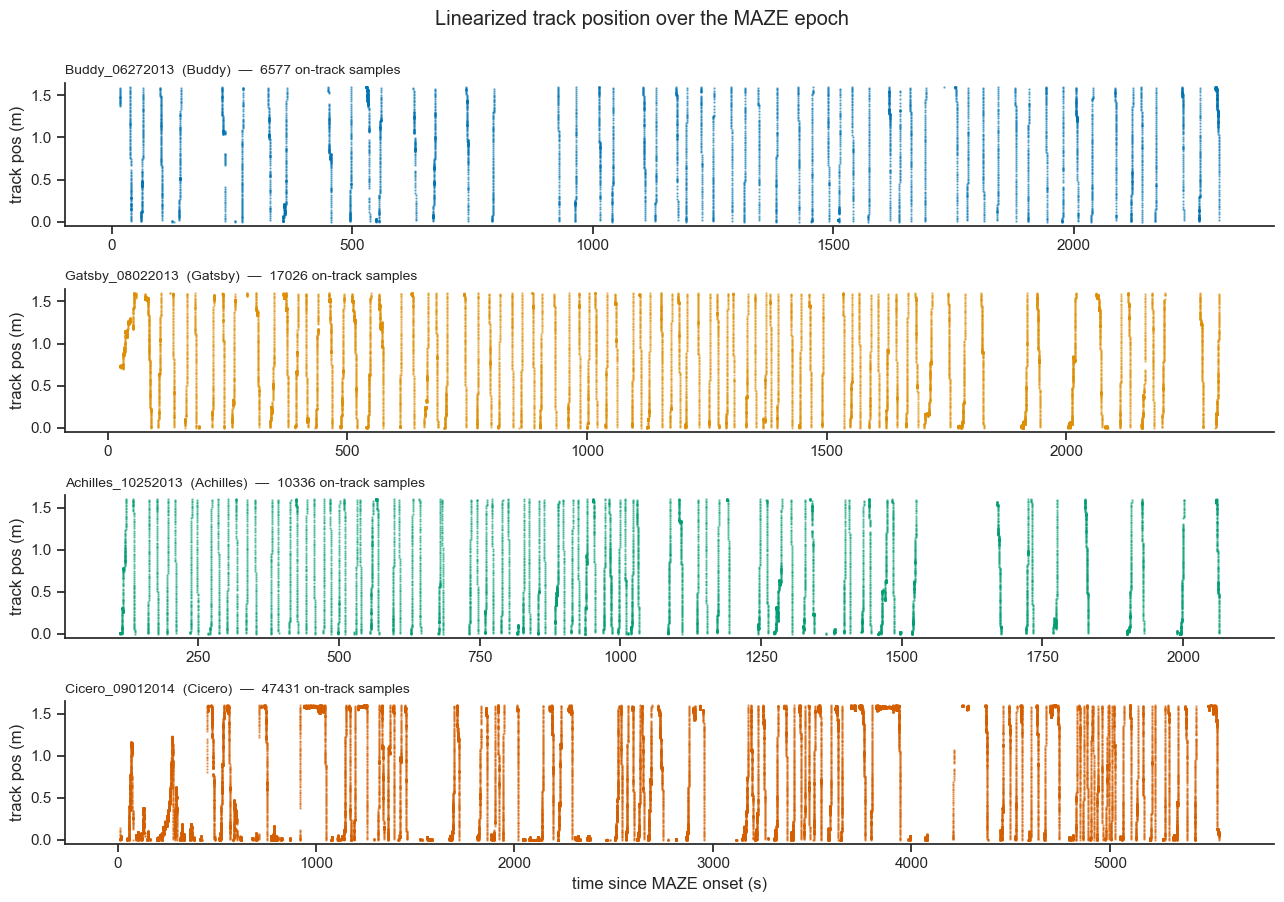

In [48]:
fig, axes = plt.subplots(len(SESSIONS), 1, figsize=(13, 9), sharex=False)
for ax, session in zip(axes, SESSIONS):
    d = pos_df[pos_df.session == session]
    ax.plot(d.t0, d.oned, '.', ms=1.5, color=rat_palette[ANIMAL[session]], alpha=0.5)
    ax.set_ylabel('track pos (m)')
    ax.set_ylim(-0.05, 1.65)
    ax.set_title(f'{session}  ({ANIMAL[session]})  —  {d.oned.notna().sum()} on-track samples',
                 loc='left', fontsize=10)
    sns.despine(ax=ax)
axes[-1].set_xlabel('time since MAZE onset (s)')
fig.suptitle('Linearized track position over the MAZE epoch', y=1.0)
fig.tight_layout()
plt.show()

## 2. Segment into leftward / rightward runs

Following the paper, we keep only samples with **speed ≥ 5 cm/s**. Because `OneDLocation` is
already the linearization *outside the reward areas*, the velocity criterion is the main operation
left to apply.

Procedure, per session:
1. Work within each contiguous on-track (non-`NaN`) stretch of `oned`.
2. Lightly smooth `oned` (Gaussian, σ≈50 ms) and take its time-derivative → signed track velocity.
3. Threshold |velocity| ≥ 5 cm/s to get *running* samples.
4. Split running samples into **runs** = maximal stretches of constant sign of velocity.
   The sign gives direction: **rightward** (0 → 1.6) vs **leftward** (1.6 → 0).

In [49]:
def contiguous_runs(mask):
    """Yield (start, stop) index pairs for each maximal True stretch in a boolean array."""
    mask = np.asarray(mask)
    if mask.sum() == 0:
        return
    d = np.diff(mask.astype(np.int8))
    starts = list(np.where(d == 1)[0] + 1)
    stops = list(np.where(d == -1)[0] + 1)
    if mask[0]:
        starts = [0] + starts
    if mask[-1]:
        stops = stops + [len(mask)]
    yield from zip(starts, stops)


def segment_runs(session):
    """Per-sample running/direction labels + a one-row-per-run summary for one session."""
    d = pos_df[pos_df.session == session].sort_values('t').reset_index()  # 'index' -> row in pos_df
    oned = d.oned.to_numpy()
    t = d.t.to_numpy()

    velocity = np.full(len(d), np.nan)   # signed track velocity (m/s)
    running = np.zeros(len(d), bool)
    direction = np.array([''] * len(d), dtype=object)
    run_id = np.full(len(d), -1)

    runs = []
    next_run = 0
    for s, e in contiguous_runs(~np.isnan(oned)):
        if e - s < MIN_RUN_SAMP:
            continue
        seg = gaussian_filter1d(oned[s:e], SMOOTH_SIGMA)
        vel = np.gradient(seg, t[s:e])
        velocity[s:e] = vel
        run_mask = np.abs(vel) >= SPEED_THRESH
        running[s:e] = run_mask
        # split running samples by constant sign of velocity
        for a, b in contiguous_runs(run_mask):
            if b - a < MIN_RUN_SAMP:
                continue
            sign = np.sign(np.nanmean(vel[a:b]))
            lab = 'rightward (0→1.6)' if sign > 0 else 'leftward (1.6→0)'
            sl = slice(s + a, s + b)
            direction[sl] = lab
            run_id[sl] = next_run
            sub = seg[a:b]
            runs.append(dict(
                session=session, rat=ANIMAL[session], run_id=next_run, direction=lab,
                t_start=t[s + a], t0_start=d.t0.to_numpy()[s + a],
                dur_s=t[s + b - 1] - t[s + a],
                pos_start=sub[0], pos_end=sub[-1],
                pos_min=sub.min(), pos_max=sub.max(), span=sub.max() - sub.min(),
                peak_speed=np.nanmax(np.abs(vel[a:b])),
            ))
            next_run += 1

    d['velocity'] = velocity
    d['running'] = running
    d['direction'] = direction
    d['run_id'] = run_id
    return d.set_index('index'), pd.DataFrame(runs)


per_sample, runs_df = zip(*(segment_runs(s) for s in SESSIONS))
per_sample = pd.concat(per_sample)
runs_df = pd.concat(runs_df, ignore_index=True)

# attach the per-sample running/direction labels back onto pos_df
pos_df = pos_df.join(per_sample[['velocity', 'running', 'direction', 'run_id']])

print(f'{len(runs_df)} runs total across the 4 sessions')
runs_df.groupby(['session', 'direction']).size().unstack(fill_value=0)

1798 runs total across the 4 sessions


direction,leftward (1.6→0),rightward (0→1.6)
session,,
Achilles_10252013,81,100
Buddy_06272013,79,56
Cicero_09012014,591,585
Gatsby_08022013,137,169


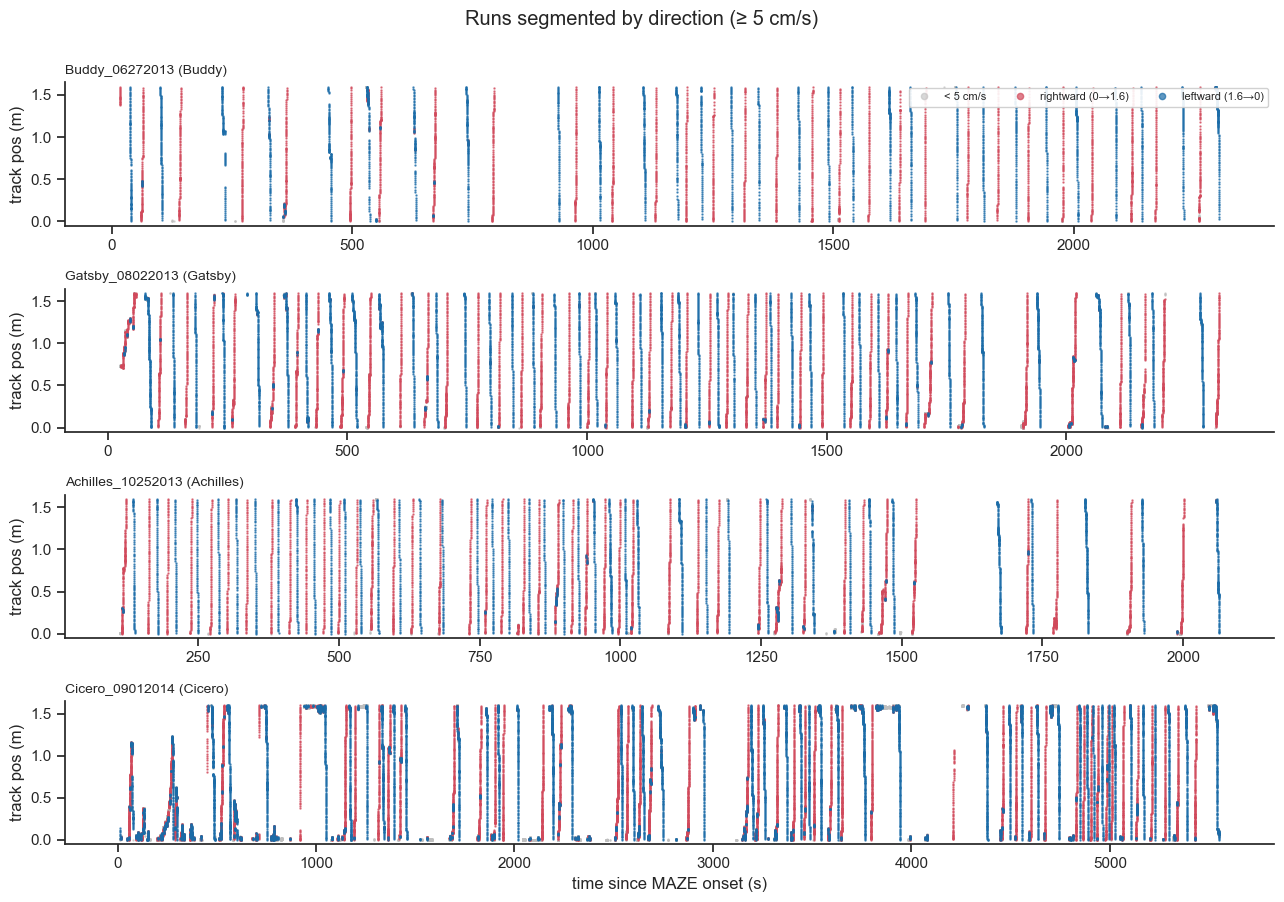

In [50]:
# Position colored by run direction; gray = on-track but below 5 cm/s (excluded)
fig, axes = plt.subplots(len(SESSIONS), 1, figsize=(13, 9))
for ax, session in zip(axes, SESSIONS):
    d = pos_df[pos_df.session == session]
    on = d[d.oned.notna()]
    slow = on[~on.running]
    ax.plot(slow.t0, slow.oned, '.', ms=1.5, color='0.75', alpha=0.6, label='< 5 cm/s')
    for lab, col in dir_palette.items():
        g = on[on.direction == lab]
        ax.plot(g.t0, g.oned, '.', ms=1.5, color=col, alpha=0.7, label=lab)
    ax.set_ylabel('track pos (m)')
    ax.set_ylim(-0.05, 1.65)
    ax.set_title(f'{session} ({ANIMAL[session]})', loc='left', fontsize=10)
    sns.despine(ax=ax)
axes[0].legend(markerscale=6, ncol=3, loc='upper right', fontsize=8, framealpha=0.9)
axes[-1].set_xlabel('time since MAZE onset (s)')
fig.suptitle('Runs segmented by direction (≥ 5 cm/s)', y=1.0)
fig.tight_layout()
plt.show()

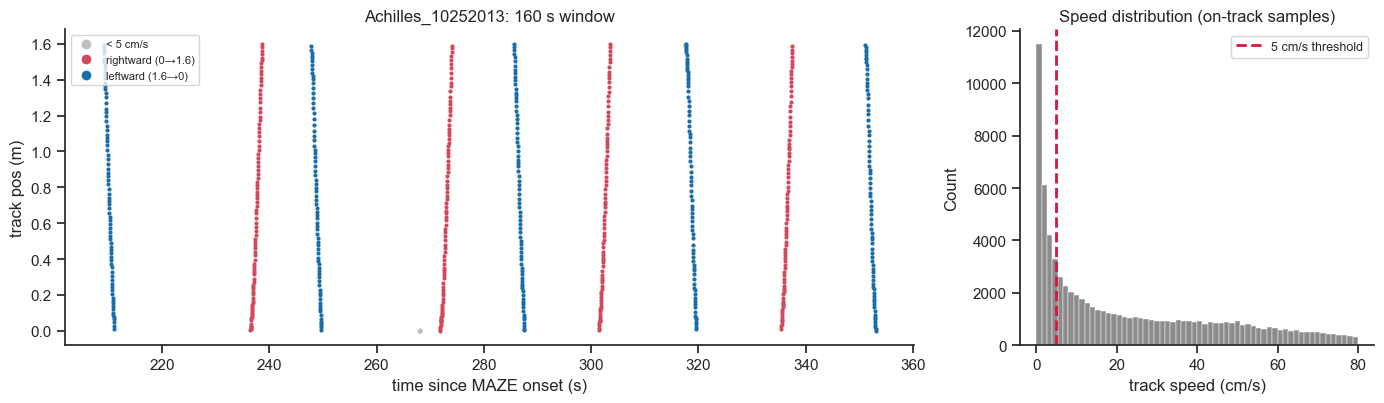

In [51]:
# Zoom on one session + the speed distribution that the 5 cm/s threshold acts on
zoom_sess = 'Achilles_10252013'
d = pos_df[pos_df.session == zoom_sess]
win = d[(d.t0 >= 200) & (d.t0 <= 360) & d.oned.notna()]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={'width_ratios': [2.4, 1]})
ax0.plot(win[~win.running].t0, win[~win.running].oned, '.', ms=4, color='0.75', label='< 5 cm/s')
for lab, col in dir_palette.items():
    g = win[win.direction == lab]
    ax0.plot(g.t0, g.oned, '.', ms=4, color=col, label=lab)
ax0.set(xlabel='time since MAZE onset (s)', ylabel='track pos (m)',
        title=f'{zoom_sess}: 160 s window')
ax0.legend(markerscale=3, fontsize=8)
sns.despine(ax=ax0)

speed = (pos_df.velocity.abs() * 100).dropna()  # cm/s, on-track samples
sns.histplot(speed[speed < 80], bins=60, ax=ax1, color='0.4')
ax1.axvline(5, color='crimson', ls='--', lw=2, label='5 cm/s threshold')
ax1.set(xlabel='track speed (cm/s)', title='Speed distribution (on-track samples)')
ax1.legend(fontsize=9)
sns.despine(ax=ax1)
fig.tight_layout()
plt.show()

## 3. Continuous trajectories spanning the full track

Is it straightforward to pull out **continuous trajectories that span the full track**? We define a
*full traversal* as a single run that starts within 20 cm of one reward end and ends within 20 cm of
the other (`pos_min < 0.2` and `pos_max > 1.4`). These are the clean, complete laps usable for
directional place-field templates.

In [52]:
END_MARGIN = 0.2  # m
runs_df['full_traversal'] = (runs_df.pos_min < END_MARGIN) & (runs_df.pos_max > TRACK_LEN - END_MARGIN)

counts = (runs_df.groupby(['session', 'direction'])
          .agg(n_runs=('run_id', 'size'), n_full=('full_traversal', 'sum'))
          .reset_index())
counts_wide = counts.pivot(index='session', columns='direction',
                           values=['n_runs', 'n_full']).reindex(SESSIONS)
print('Runs and full-track traversals by session and direction:')
counts_wide

Runs and full-track traversals by session and direction:


n_runs                             n_full  \
direction         leftward (1.6→0) rightward (0→1.6) leftward (1.6→0)   
session                                                                 
Buddy_06272013                  79                56               19   
Gatsby_08022013                137               169               26   
Achilles_10252013               81               100               36   
Cicero_09012014                591               585               17   

                                     
direction         rightward (0→1.6)  
session                              
Buddy_06272013                   20  
Gatsby_08022013                  21  
Achilles_10252013                30  
Cicero_09012014                  15

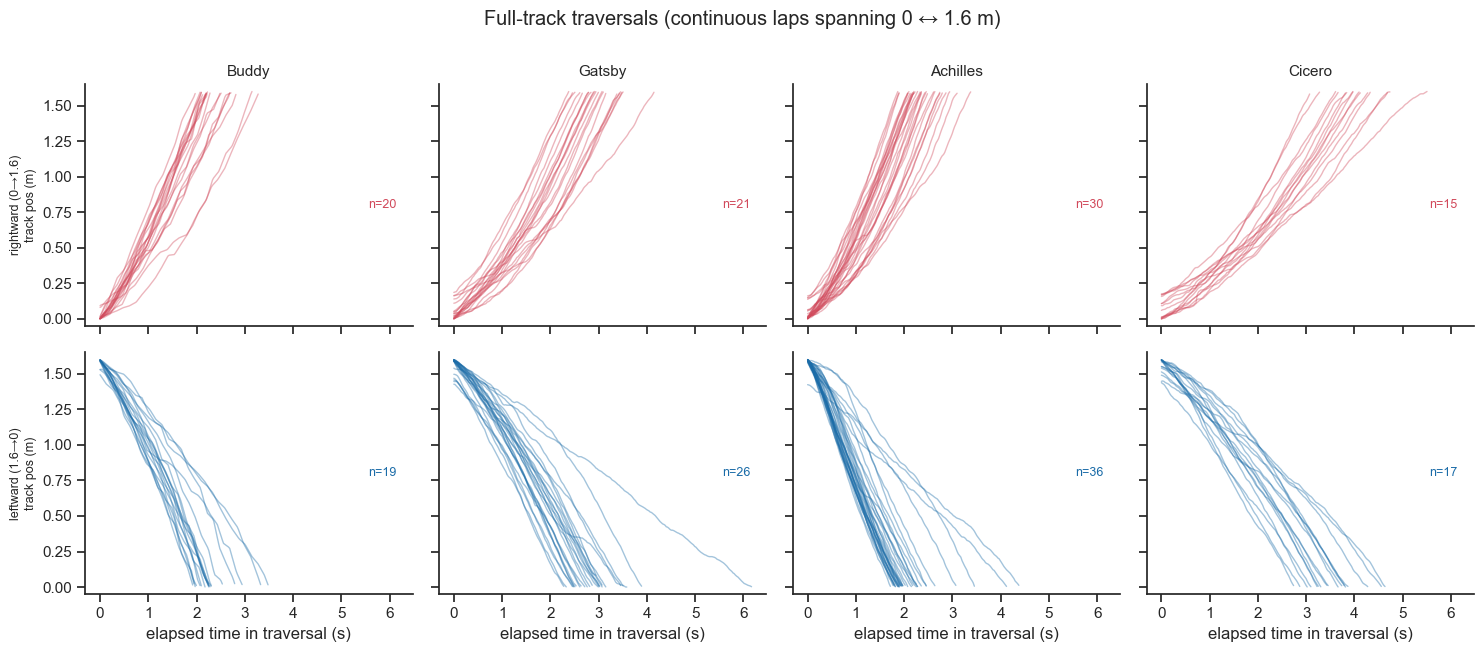

In [53]:
# Each full traversal as a continuous position-vs-elapsed-time trace, by direction
fig, axes = plt.subplots(2, len(SESSIONS), figsize=(15, 6.5), sharex=True, sharey=True)
for j, session in enumerate(SESSIONS):
    rd = runs_df[(runs_df.session == session) & runs_df.full_traversal]
    sd = pos_df[pos_df.session == session]
    for i, (lab, col) in enumerate(dir_palette.items()):
        ax = axes[i, j]
        for rid in rd[rd.direction == lab].run_id:
            tr = sd[sd.run_id == rid].sort_values('t')
            ax.plot(tr.t0 - tr.t0.iloc[0], tr.oned, color=col, alpha=0.4, lw=1)
        ax.set_ylim(-0.05, 1.65)
        n = (rd.direction == lab).sum()
        if i == 0:
            ax.set_title(f'{ANIMAL[session]}', fontsize=11)
        ax.text(0.95, 0.5, f'n={n}', transform=ax.transAxes, ha='right', va='center',
                fontsize=9, color=col)
        if j == 0:
            ax.set_ylabel(f'{lab}\ntrack pos (m)', fontsize=9)
        sns.despine(ax=ax)
for ax in axes[1]:
    ax.set_xlabel('elapsed time in traversal (s)')
fig.suptitle('Full-track traversals (continuous laps spanning 0 ↔ 1.6 m)', y=1.0)
fig.tight_layout()
plt.show()

### Unfragmented vs. fragmented traversals

A *full traversal* above is one **single run** that spans the track end-to-end (unfragmented). But
the rat also completes some end-to-end crossings in **multiple pieces** — broken up by a pause that
drops below 5 cm/s mid-track, or by a tracking gap. To quantify this, we count every actual
end-to-end **crossing** (an alternation between the two reward-end zones, `oned < 0.2` ↔ `> 1.4`)
and compare against the single-run traversals:

- **unfragmented** = crossing captured by one continuous run (== the `full_traversal` runs above)
- **fragmented** = crossing that required ≥ 2 fragments (`n_crossings − n_unfragmented`)

In [54]:
def count_crossings(session):
    """End-to-end crossings (reward-zone alternations), split by direction, for one session."""
    d = pos_df[pos_df.session == session].sort_values('t')
    oned = d.oned.to_numpy()
    on = ~np.isnan(oned)
    zone = np.where(on & (oned < END_MARGIN), -1,
                    np.where(on & (oned > TRACK_LEN - END_MARGIN), 1, 0))
    visits = zone[zone != 0]
    visits = visits[np.r_[True, np.diff(visits) != 0]]   # collapse repeats -> alternation sequence
    step = np.diff(visits)
    return {'rightward (0→1.6)': int((step == 2).sum()),   # bottom -> top
            'leftward (1.6→0)':  int((step == -2).sum())}   # top -> bottom

cross = pd.DataFrame([{'session': s, 'direction': k, 'n_crossings': v}
                      for s in SESSIONS for k, v in count_crossings(s).items()])
frag = (cross.merge(counts[['session', 'direction', 'n_full']], on=['session', 'direction'])
        .rename(columns={'n_full': 'unfragmented'}))
frag['fragmented'] = frag.n_crossings - frag.unfragmented
frag['pct_clean'] = (100 * frag.unfragmented / frag.n_crossings).round(0)

by_session = (frag.groupby('session', sort=False)[['n_crossings', 'unfragmented', 'fragmented']]
              .sum().reindex(SESSIONS))
by_session['pct_clean'] = (100 * by_session.unfragmented / by_session.n_crossings).round(0)
totals = by_session[['n_crossings', 'unfragmented', 'fragmented']].sum()
print(f"Across all 4 sessions: {totals.n_crossings} end-to-end crossings | "
      f"{totals.unfragmented} unfragmented ({100*totals.unfragmented/totals.n_crossings:.0f}%) | "
      f"{totals.fragmented} fragmented")
by_session

Across all 4 sessions: 317 end-to-end crossings | 184 unfragmented (58%) | 133 fragmented


,n_crossings,unfragmented,fragmented,pct_clean
session,,,,
Buddy_06272013,57,39,18,68.0
Gatsby_08022013,84,47,37,56.0
Achilles_10252013,84,66,18,79.0
Cicero_09012014,92,32,60,35.0


### How fragmented are the pauses?

For each pair of consecutive **same-direction** runs that are *not* separated by an end-zone visit
(i.e. two fragments of one crossing), the gap between them is a *fragmenting pause*. We measure each
pause's duration and whether it is an on-track speed-dip (rat slowed below 5 cm/s but stayed tracked)
or a tracking-gap dropout (`NaN`).

273 fragmenting pauses across 4 sessions
  median = 0.23 s | 90th pct = 0.92 s | max = 5.84 s
  brief (<1 s): 90%   (<0.5 s: 78%) | prolonged (>3 s): 3%
  on-track speed-dip: 74%  |  tracking gap: 26%


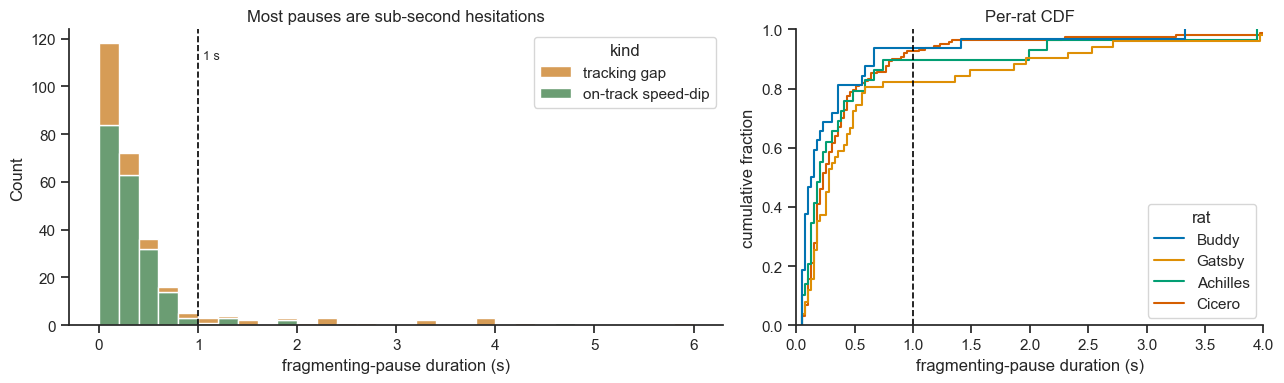

In [55]:
def fragmenting_pauses(session):
    """Gaps between consecutive same-direction runs of one crossing (no end-zone in between)."""
    d = pos_df[pos_df.session == session].sort_values('t').reset_index(drop=True)
    t = d.t.to_numpy(); oned = d.oned.to_numpy(); rid = d.run_id.to_numpy()
    on = ~np.isnan(oned)
    sign = {'rightward (0→1.6)': 1, 'leftward (1.6→0)': -1}
    # (first_idx, last_idx, direction) per run_id, ordered in time
    runs = []
    for r, g in d[d.run_id >= 0].groupby('run_id'):
        runs.append((g.index[0], g.index[-1] + 1, sign[g.direction.iloc[0]]))
    runs.sort()
    out = []
    for (s0, e0, d0), (s1, e1, d1) in zip(runs, runs[1:]):
        if d0 != d1:
            continue
        seg = oned[e0:s1]
        on_seg = on[e0:s1]
        if np.any(on_seg & ((seg < END_MARGIN) | (seg > TRACK_LEN - END_MARGIN))):
            continue  # reached an end -> a new crossing, not an internal fragment
        out.append(dict(session=session, rat=ANIMAL[session],
                        gap_s=t[s1] - t[e0 - 1],
                        nan_frac=np.isnan(seg).mean() if len(seg) else 0.0))
    return out

pauses = pd.DataFrame([p for s in SESSIONS for p in fragmenting_pauses(s)])
pauses['kind'] = np.where(pauses.nan_frac > 0.5, 'tracking gap', 'on-track speed-dip')

q = pauses.gap_s.describe(percentiles=[.5, .9, .95])
print(f"{len(pauses)} fragmenting pauses across {len(SESSIONS)} sessions")
print(f"  median = {q['50%']:.2f} s | 90th pct = {q['90%']:.2f} s | max = {pauses.gap_s.max():.2f} s")
print(f"  brief (<1 s): {100*(pauses.gap_s < 1).mean():.0f}%   "
      f"(<0.5 s: {100*(pauses.gap_s < 0.5).mean():.0f}%) | "
      f"prolonged (>3 s): {100*(pauses.gap_s >= 3).mean():.0f}%")
print(f"  on-track speed-dip: {100*(pauses.kind == 'on-track speed-dip').mean():.0f}%  |  "
      f"tracking gap: {100*(pauses.kind == 'tracking gap').mean():.0f}%")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [1.4, 1]})
sns.histplot(data=pauses, x='gap_s', hue='kind', bins=np.arange(0, 6.1, 0.2),
             multiple='stack', ax=ax0,
             palette={'on-track speed-dip': '#3a7d44', 'tracking gap': '#c97b1e'})
ax0.axvline(1, color='k', ls='--', lw=1.2)
ax0.text(1.05, ax0.get_ylim()[1]*0.9, '1 s', fontsize=9)
ax0.set(xlabel='fragmenting-pause duration (s)', title='Most pauses are sub-second hesitations')
sns.despine(ax=ax0)

sns.ecdfplot(data=pauses, x='gap_s', hue='rat', palette=rat_palette, ax=ax1)
ax1.axvline(1, color='k', ls='--', lw=1.2)
ax1.set(xlabel='fragmenting-pause duration (s)', ylabel='cumulative fraction',
        title='Per-rat CDF', xlim=(0, 4))
sns.despine(ax=ax1)
fig.tight_layout()
plt.show()

## 4. Stitch fragments into continuous laps

Since 90% of the fragmenting pauses are < 1 s, we recover the broken crossings by **merging
consecutive same-direction runs whose gap is < 1 s** (and that don't reach a reward end in
between) into a single **lap**. The two gap types are handled differently:

- **on-track speed-dip** (the rat slowed below 5 cm/s but stayed tracked): keep **all the valid
  samples** in the gap — the trajectory is real, we just don't want to throw it away.
- **tracking dropout** (`NaN`): **stitch across it** by linearly interpolating position over the gap.

The result is `oned_stitched` (a continuous within-lap position) and a `laps_df`, on which we
re-evaluate which crossings now span the full track.

In [56]:
STITCH_MAX_GAP = 1.0  # s; merge same-direction runs separated by a shorter gap

def stitch_laps(session):
    """Merge <1 s same-direction run gaps into laps; return per-sample cols + lap records."""
    d = pos_df[pos_df.session == session].sort_values('t').reset_index()  # 'index' -> pos_df row
    t = d.t.to_numpy(); oned = d.oned.to_numpy(); rid = d.run_id.to_numpy()
    on = ~np.isnan(oned)
    sign = {'rightward (0→1.6)': 1, 'leftward (1.6→0)': -1}

    runs = [(g.index[0], g.index[-1] + 1, sign[g.direction.iloc[0]])
            for _, g in d[d.run_id >= 0].groupby('run_id')]
    runs.sort()

    # group adjacent runs that should be stitched together
    groups, cur = [], [list(runs[0])]
    for s, e, dr in runs[1:]:
        ps, pe, pd_ = cur[-1]
        between = oned[pe:s]
        touches_end = np.any(on[pe:s] & ((between < END_MARGIN) | (between > TRACK_LEN - END_MARGIN)))
        if dr == pd_ and (t[s] - t[pe - 1]) < STITCH_MAX_GAP and not touches_end:
            cur.append([s, e, dr])
        else:
            groups.append(cur); cur = [[s, e, dr]]
    groups.append(cur)

    lap_id = np.full(len(d), -1)
    oned_st = oned.copy()
    laps = []
    for k, grp in enumerate(groups):
        i0, i1, dr = grp[0][0], grp[-1][1], grp[0][2]
        sl = slice(i0, i1)
        lap_id[sl] = k
        seg = oned[sl]
        idx = np.arange(len(seg)); v = ~np.isnan(seg)
        seg_i = np.interp(idx, idx[v], seg[v])     # bridge NaN dropouts within the lap
        oned_st[sl] = seg_i
        n_dip = int((v & (rid[sl] < 0)).sum())     # valid sub-threshold samples kept
        n_bridge = int((~v).sum())                 # NaN samples bridged
        laps.append(dict(
            session=session, rat=ANIMAL[session], lap_id=k,
            direction='rightward (0→1.6)' if dr > 0 else 'leftward (1.6→0)',
            n_frag=len(grp), dur_s=t[i1 - 1] - t[i0],
            pos_min=seg_i.min(), pos_max=seg_i.max(), span=seg_i.max() - seg_i.min(),
            n_dip=n_dip, n_bridge=n_bridge,
            bridged=n_bridge > 0, stitched=len(grp) > 1))
    d['lap_id'] = lap_id
    d['oned_stitched'] = oned_st
    return d.set_index('index')[['lap_id', 'oned_stitched']], pd.DataFrame(laps)

per_lap, laps_df = zip(*(stitch_laps(s) for s in SESSIONS))
laps_df = pd.concat(laps_df, ignore_index=True)
pos_df = pos_df.join(pd.concat(per_lap))

laps_df['full_traversal'] = (laps_df.pos_min < END_MARGIN) & (laps_df.pos_max > TRACK_LEN - END_MARGIN)

before = int(runs_df.full_traversal.sum())
after = int(laps_df.full_traversal.sum())
print(f'Runs {len(runs_df)} -> laps {len(laps_df)}  '
      f'({int((laps_df.n_frag > 1).sum())} laps stitch >=2 fragments)')
print(f'Full-track traversals: {before} (single-run) -> {after} (stitched)  +{after - before}')
ft = laps_df[laps_df.full_traversal]
print(f'  of the {after} stitched full traversals: {int(ft.stitched.sum())} required stitching, '
      f'{int(ft.bridged.sum())} bridged a tracking dropout')

cmp = pd.DataFrame({
    'single_run': runs_df[runs_df.full_traversal].groupby('session').size(),
    'stitched':   laps_df[laps_df.full_traversal].groupby('session').size(),
}).reindex(SESSIONS)
cmp['recovered'] = cmp.stitched - cmp.single_run
cmp

Runs 1798 -> laps 1551  (171 laps stitch >=2 fragments)
Full-track traversals: 184 (single-run) -> 238 (stitched)  +54
  of the 238 stitched full traversals: 57 required stitching, 21 bridged a tracking dropout


,single_run,stitched,recovered
session,,,
Buddy_06272013,39,48,9
Gatsby_08022013,47,64,17
Achilles_10252013,66,75,9
Cicero_09012014,32,51,19


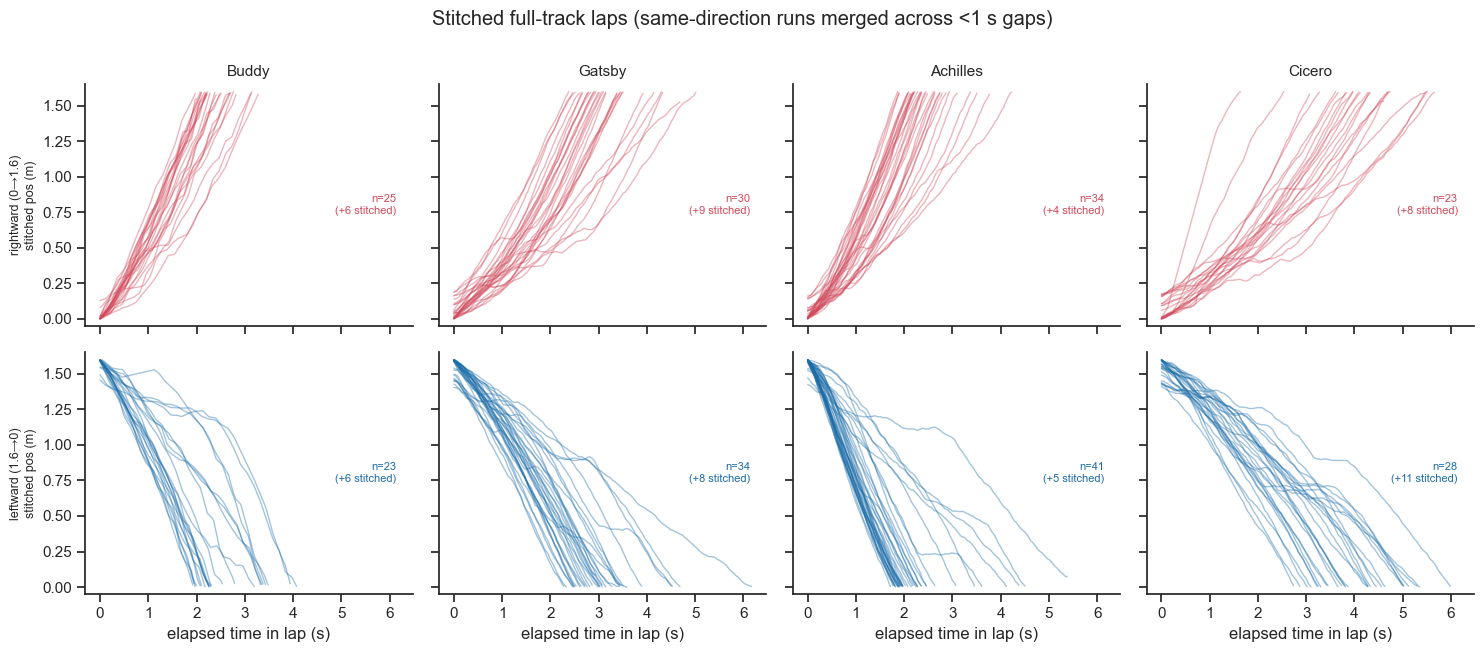

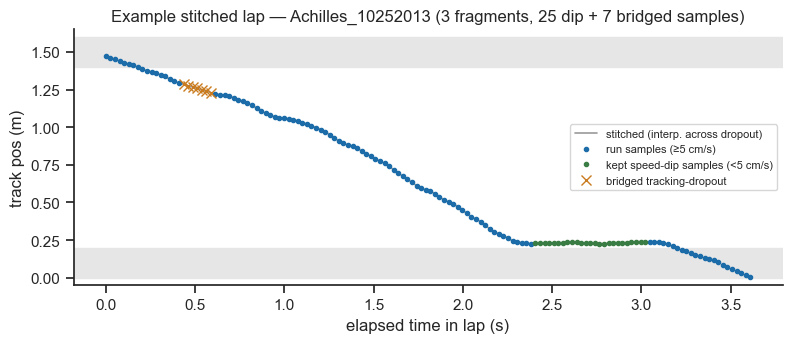

In [57]:
# Stitched full-track laps (continuous oned_stitched), by rat and direction
fig, axes = plt.subplots(2, len(SESSIONS), figsize=(15, 6.5), sharex=True, sharey=True)
for j, session in enumerate(SESSIONS):
    ld = laps_df[(laps_df.session == session) & laps_df.full_traversal]
    sd = pos_df[pos_df.session == session]
    for i, (lab, col) in enumerate(dir_palette.items()):
        ax = axes[i, j]
        for lid in ld[ld.direction == lab].lap_id:
            tr = sd[sd.lap_id == lid].sort_values('t')
            ax.plot(tr.t0 - tr.t0.iloc[0], tr.oned_stitched, color=col, alpha=0.4, lw=1)
        ax.set_ylim(-0.05, 1.65)
        n = int((ld.direction == lab).sum())
        n_new = int(((ld.direction == lab) & ld.stitched).sum())
        if i == 0:
            ax.set_title(ANIMAL[session], fontsize=11)
        ax.text(0.95, 0.5, f'n={n}\n(+{n_new} stitched)', transform=ax.transAxes,
                ha='right', va='center', fontsize=8, color=col)
        if j == 0:
            ax.set_ylabel(f'{lab}\nstitched pos (m)', fontsize=9)
        sns.despine(ax=ax)
for ax in axes[1]:
    ax.set_xlabel('elapsed time in lap (s)')
fig.suptitle('Stitched full-track laps (same-direction runs merged across <1 s gaps)', y=1.0)
fig.tight_layout()
plt.show()

# Illustrative example: prefer a lap showing BOTH a kept speed-dip and a bridged dropout
cand = laps_df[laps_df.full_traversal & (laps_df.n_frag >= 2)]
both = cand[(cand.n_dip > 0) & (cand.n_bridge > 0)]
ex = (both if len(both) else cand).assign(tot=lambda x: x.n_dip + x.n_bridge).sort_values(
    'tot', ascending=False)
if len(ex):
    row = ex.iloc[0]
    sd = pos_df[(pos_df.session == row.session)].sort_values('t')
    tr = sd[sd.lap_id == row.lap_id]
    t_rel = (tr.t0 - tr.t0.iloc[0]).to_numpy()
    fig, ax = plt.subplots(figsize=(8, 3.6))
    ax.plot(t_rel, tr.oned_stitched, '-', color='0.6', lw=1.2, zorder=1,
            label='stitched (interp. across dropout)')
    in_run = tr.run_id >= 0
    ax.plot(t_rel[in_run], tr.oned.to_numpy()[in_run], '.', ms=6, color=dir_palette[row.direction],
            label='run samples (≥5 cm/s)')
    dip = (~in_run) & tr.oned.notna()
    ax.plot(t_rel[dip], tr.oned.to_numpy()[dip], '.', ms=6, color='#3a7d44',
            label='kept speed-dip samples (<5 cm/s)')
    drop = tr.oned.isna()
    ax.plot(t_rel[drop], tr.oned_stitched.to_numpy()[drop], 'x', ms=7, color='#c97b1e',
            label='bridged tracking-dropout')
    ax.axhspan(0, END_MARGIN, color='0.9'); ax.axhspan(TRACK_LEN - END_MARGIN, TRACK_LEN, color='0.9')
    ax.set(xlabel='elapsed time in lap (s)', ylabel='track pos (m)', ylim=(-0.05, 1.65),
           title=f'Example stitched lap — {row.session} ({row.n_frag} fragments, '
                 f'{row.n_dip} dip + {row.n_bridge} bridged samples)')
    ax.legend(fontsize=8, loc='center right')
    sns.despine(ax=ax)
    fig.tight_layout()
    plt.show()

# Part II — Neural decoding: Transformer vs CEBRA

We reproduce the CEBRA hippocampus analysis (Schneider, Lee & Mathis, *Nature* 2023, Figs 1–2) on
these four rats. Preprocessing is **ported from pi-VAE** (`rat_preprocess_data.py`, Zhou & Wei 2020):
25 ms pyramidal spike counts, on-track (non-NaN) position kept with **no speed threshold**, and
round-trip **trials** parsed from the `rolling_max` turnaround detector (boundaries < 1 m apart
removed). The label is the paper's **3-D vector** `[position, right, left]`.

The **main comparison** is between **shared-model** variants of both decoders, read out per rat:

1. a multisession **RoPE Transformer** decoder (`Bat_Transformer_Decoder`, one model over all rats),
   fed **one-way traversals**;
2. a multisession **CEBRA** embedding (jointly fit across rats, `fit([X_rat…],[y_rat…])` +
   `transform(session_id=…)`), in **pos** and **posdir** label settings, decoded with a kNN read-out;
3. a **unified CEBRA** embedding (`UnifiedSolver`: ONE shared encoder over the neuron-concatenation of
   all rats with input masking; `Demo_hippocampus_unified`), in **pos** and **posdir**, decoded with
   the same kNN read-out.

**Single-session CEBRA** (per rat) is also reported for reference / comparison to the paper, and the
single-session embeddings are used for the visualization (Fig 2b) and topology (Fig 2e–g).

Both decoders share the same **k = 3 cross-validation** (each fold is test once; the other two folds
are train, with a small validation hold-out for the Transformer; metrics averaged over the three test
folds). All trained models (Transformer per fold, every CEBRA fit) are **cached to disk** under
`tmp/grosmark_cache/`, so re-running the notebook reloads instead of retraining (set
`FORCE_RETRAIN = True` to recompute).

## 5. Bin spikes and build the decoding dataset

In [58]:
import sys, os, json, hashlib, torch
sys.path.insert(0, '/home/alowet/Documents/code/digitalbat')
from torch.utils.data import DataLoader
from torch import nn
from digitalbat.datasets.data import BehaviorSpikeDataset
from digitalbat.models.decoder import Bat_Transformer_Decoder, bat_decoder_trainer
from cebra import CEBRA
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier

device = 'cuda' if torch.cuda.is_available() else 'cpu'

# ---- neural-analysis config (ported from pi-VAE rat_preprocess_data.py / Zhou & Wei 2020) ----
NEUR_BIN = 0.025      # s, 25 ms windows (pi-VAE bin_size = 25)
MIN_TRIAL = 10        # bins; drop round-trips below the CEBRA receptive field (pi-VAE keeps all)
N_FOLDS = 3           # k = 3 cross-validation
VAL_EVERY = 5         # Transformer: every 5th train+val round-trip held out for early stopping
CEBRA_ITER = 6000     # CEBRA max_iterations
CEBRA_DECODE_DIM = 32 # fallback decode dim; OVERRIDDEN by validation selection (CEBRA_DIM_GRID) in the decode cell
N_TRIALS = 20         # Optuna trials for the Transformer (repo convention)
MAX_EPOCHS = 400      # Transformer training epochs (early-stopped)
KNN_N = 36            # kNN neighbours for decoding (CEBRA demo convention)
CEBRA_DIM_GRID = [8, 16, 32, 64, 128]   # decode-dim sweep, selected by validation R^2
SEED = 0
rng = np.random.default_rng(SEED)
CV_ROUNDS = [{'test': r} for r in range(N_FOLDS)]   # each fold is test once; other two are train(+val)

# ---- disk cache for trained models / results (kept out of git, under tmp/) ----
CACHE_DIR = '/home/alowet/Documents/code/digitalbat/tmp/grosmark_cache'
os.makedirs(CACHE_DIR, exist_ok=True)
FORCE_RETRAIN = False                # set True to ignore cached models and retrain

# ---- topological data analysis (CEBRA paper / Demo_cohomology recipe) ----
TDA_DIMS = [3]                  # headline two-sphere result (dim survey is slow; see below)
TDA_STEPS = 10000               # CEBRA training steps for the real embeddings (paper)
TDA_NPOINTS = 1000              # randomly sampled points (paper/demo)
TDA_SEED = 111                  # demo seed for point sampling
TDA_MAXDIM = 2                  # cohomology up to H2 (demo coeff 47)
TDA_COEFF = 47
TDA_MARGIN = 1.1                # threshold = max shuffled-label lifespan x 1.1 (demo)
TDA_N_SHUFFLE = 200             # shuffled-LABEL null models for H0/H1 (maxdim=1 ripser, fast)
TDA_N_SHUFFLE_H2 = 20           # of those, this many also run maxdim=2 for the H2 threshold (beta2=0 is robust)
TDA_NULL_STEPS = 2000           # steps for null models (shuffled labels are structureless; validated)


def _cfg_sig():
    cfg = dict(sessions=SESSIONS, bin=NEUR_BIN, min_trial=MIN_TRIAL, folds=N_FOLDS,
               cebra_iter=CEBRA_ITER, n_trials=N_TRIALS, max_epochs=MAX_EPOCHS)
    return hashlib.md5((json.dumps(cfg, sort_keys=True) + '|preln').encode()).hexdigest()[:8]


def cache_path(name):
    os.makedirs(CACHE_DIR, exist_ok=True)   # self-healing if the dir was removed
    return os.path.join(CACHE_DIR, f'{_cfg_sig()}_{name}')


def rolling_max(x):
    """pi-VAE turnaround detector: indices near a track end that are a local extremum (+/-20 samples)."""
    idx_split = []
    for idx, val in enumerate(x):
        if val < 0.025 or val > 1.575:
            tmp = x[max(idx - 20, 0):min(idx + 20, len(x))]
            if val == min(tmp) or val == max(tmp):
                idx_split.append(idx)
    return np.array(idx_split)


def build_session(session):
    """pi-VAE recipe: 25 ms pyramidal spike counts, on-track (non-NaN) position kept (no speed cut),
    round-trips parsed from `rolling_max` turnarounds (boundaries <1 m apart removed).

      - `trials` : round-trips (left end -> right -> left) = CV split unit + CEBRA running stream.
      - `oneway` : the two one-way traversals of each round-trip = Transformer sequences.
    """
    with h5py.File(os.path.join(DATA_DIR, f'{session}_sessInfo.mat'), 'r') as f:
        si = f['sessInfo']
        st = np.asarray(si['Spikes']['SpikeTimes']).squeeze()
        sid = np.asarray(si['Spikes']['SpikeIDs']).squeeze()
        pyr = np.sort(np.asarray(si['Spikes']['PyrIDs']).squeeze().astype(int))
        ts = np.asarray(si['Position']['TimeStamps']).squeeze()
        oned = np.asarray(si['Position']['OneDLocation']).squeeze()
        maze = np.asarray(si['Epochs']['MazeEpoch']).squeeze()
    t0, t1 = maze
    edges = np.arange(t0, t1 + NEUR_BIN, NEUR_BIN)
    centers = edges[:-1] + NEUR_BIN / 2
    neural = np.stack([np.histogram(st[sid == c], bins=edges)[0] for c in pyr], axis=1).astype(np.float32)
    # position interpolated to bin centres; bins far from any real sample are off-track (NaN)
    v = ~np.isnan(oned); tt = ts[v]
    pos = np.interp(centers, tt, oned[v], left=np.nan, right=np.nan)
    near = np.clip(np.searchsorted(tt, centers), 1, len(tt) - 1)
    dnear = np.minimum(np.abs(centers - tt[near]), np.abs(centers - tt[near - 1]))
    pos[dnear > 0.2] = np.nan
    ps = gaussian_filter1d(np.nan_to_num(pos, nan=np.nanmean(pos)), 2)
    direction = (np.gradient(ps, NEUR_BIN) > 0).astype(int)        # 1 rightward, 0 leftward

    onbins = np.where(~np.isnan(pos))[0]                           # on-track bins (no speed threshold)
    locvec = pos[onbins]
    B = rolling_max(locvec)
    B = np.delete(B, np.where(np.abs(np.diff(locvec[B])) < 1)[0])  # drop boundaries <1 m apart
    trav = [(B[k], B[k + 1]) for k in range(len(B) - 1)]           # one-way traversals (compressed idx)
    start = next((k for k in range(len(trav)) if locvec[trav[k][0]] < 0.8), 0)  # begin at a left end
    trials, folds, oneway = [], [], []
    j = start
    while j + 1 < len(trav):
        a, b = trav[j][0], trav[j + 1][1]                          # round-trip spans two traversals
        rt = onbins[a:b]
        if len(rt) >= MIN_TRIAL:
            tid = len(trials); fold = tid % N_FOLDS
            trials.append(rt); folds.append(fold)
            for (s, e) in (trav[j], trav[j + 1]):
                oneway.append({'idx': onbins[s:e], 'fold': fold, 'trial': tid})
        j += 2
    return dict(session=session, rat=ANIMAL[session], neural=neural, pos=pos, direction=direction,
                K=len(pyr), trials=trials, folds=np.array(folds), oneway=oneway)


def cv_split(d, cv):
    """Round-trip trial ids per role: test = 1 fold; train+val = other 2 folds (val = 1/VAL_EVERY)."""
    test = [i for i, f in enumerate(d['folds']) if f == cv['test']]
    tv = [i for i, f in enumerate(d['folds']) if f != cv['test']]
    val = tv[::VAL_EVERY] if len(tv) >= VAL_EVERY else tv[-1:]
    vs = set(val)
    return {'train': [i for i in tv if i not in vs], 'val': val, 'test': test, 'trainval': tv}


def trials_of(d, ids):
    return [d['trials'][i] for i in ids]


def oneway_of(d, ids):
    s = set(ids)
    return [o['idx'] for o in d['oneway'] if o['trial'] in s]


def idx_cat(d, idx_list, what='neural'):
    idx = np.concatenate(idx_list) if len(idx_list) else np.zeros(0, int)
    return d['neural'][idx] if what == 'neural' else d[what][idx]


SESS = {s: build_session(s) for s in SESSIONS}
trial_summary = pd.DataFrame([{
    'session': s, 'rat': ANIMAL[s], 'n_pyr': SESS[s]['K'], 'n_roundtrips': len(SESS[s]['trials']),
    'n_oneway': len(SESS[s]['oneway']),
    **{f'fold{f}': int((SESS[s]['folds'] == f).sum()) for f in range(N_FOLDS)},
    'on_track_bins': int(sum(len(t) for t in SESS[s]['trials'])),
} for s in SESSIONS]).set_index('session')
trial_summary

,rat,n_pyr,n_roundtrips,n_oneway,fold0,fold1,fold2,on_track_bins
session,,,,,,,,
Buddy_06272013,Buddy,48,27,54,9,9,9,7402
Gatsby_08022013,Gatsby,66,41,82,14,14,13,17822
Achilles_10252013,Achilles,120,42,84,14,14,14,12451
Cicero_09012014,Cicero,55,46,92,16,15,15,48661


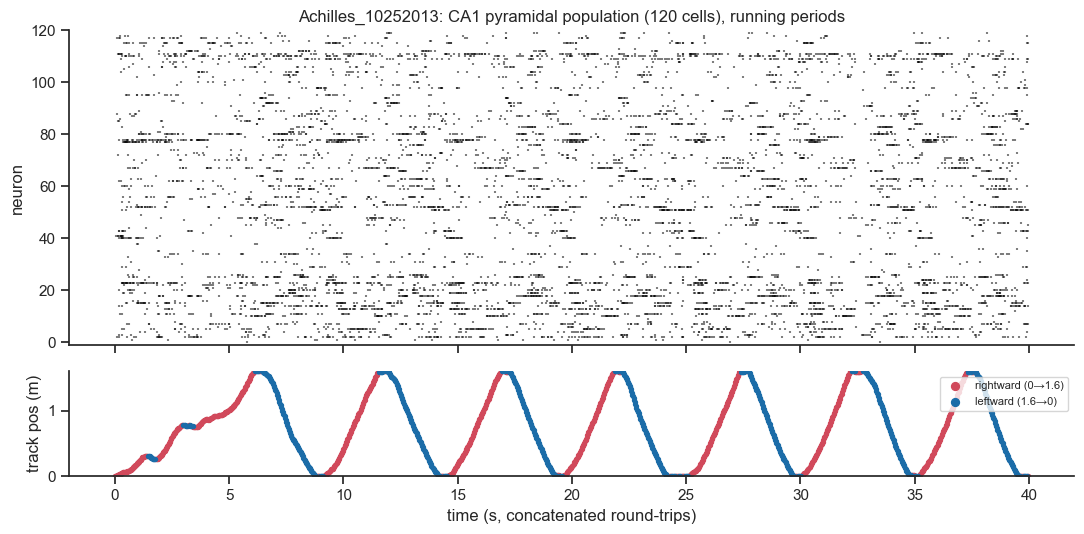

In [59]:
# Fig 1c-style overview for Achilles: population raster (top) + track position colored by direction
PRIMARY = 'Achilles_10252013'   # 120 pyramidal cells -- the canonical CEBRA hippocampus rat
d = SESS[PRIMARY]
all_idx = np.concatenate(d['trials'])          # all running bins (round-trips concatenated)
tt = np.arange(len(all_idx)) * NEUR_BIN
w0, w1 = 0, 40                                  # seconds of running data to display
sel = (tt >= w0) & (tt < w1)
neur_w = d['neural'][all_idx][sel]
pos_w = d['pos'][all_idx][sel]
dir_w = d['direction'][all_idx][sel]
tt_w = tt[sel]

fig, (axr, axp) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})
spk_t, spk_n = np.where(neur_w > 0)
axr.scatter(tt_w[spk_t], spk_n, s=2, c='k', marker='|', alpha=0.5)
axr.set(ylabel='neuron', title=f'{PRIMARY}: CA1 pyramidal population ({d["K"]} cells), running periods')
axr.set_ylim(-1, d['K'])
for lab, dv, col in [('rightward (0→1.6)', 1, dir_palette['rightward (0→1.6)']),
                     ('leftward (1.6→0)', 0, dir_palette['leftward (1.6→0)'])]:
    m = dir_w == dv
    axp.scatter(tt_w[m], pos_w[m], s=8, c=col, label=lab)
axp.set(xlabel='time (s, concatenated round-trips)', ylabel='track pos (m)', ylim=(0, 1.6))
axp.legend(markerscale=2, fontsize=8, loc='upper right')
for ax in (axr, axp):
    sns.despine(ax=ax)
fig.tight_layout()
plt.show()

## 6. CEBRA embeddings and visualization (Fig 2b)

We train CEBRA on each rat's running spikes in three label settings — **posdir** (position +
left/right), **pos** (position only) and **Time** (label-free) — plus a **shuffled** control
(position labels permuted). Following the paper we use `offset10-model`, cosine distance,
`output_dimension=3` for visualization, and plot the 3D embedding coloured by position and by
direction. A structured "loop" of latent dynamics around the track is the expected place-cell
signature; shuffled labels should give an unstructured cloud.

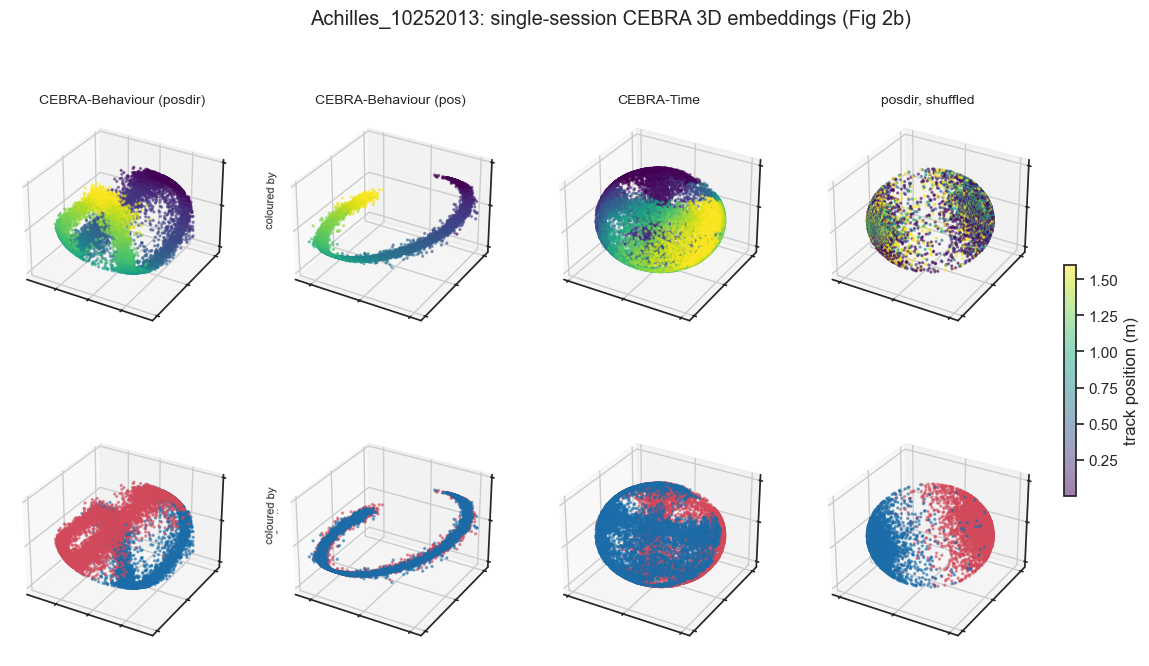

In [60]:
import cebra.data
import cebra.models
import cebra.solver

CEBRA_CACHE = {}


def cebra_label(variant, pos, direction, shuffle=False):
    """Paper's label: None (Time), [pos] (pos), or [pos, right, left] (posdir)."""
    if variant == 'time':
        return None
    pos = pos.astype(np.float32)
    if shuffle:
        pos = rng.permutation(pos)
    if variant == 'pos':
        return pos[:, None]
    dr = direction.astype(int)
    return np.c_[pos, (dr == 1), (dr == 0)].astype(np.float32)     # [position, right, left]


def new_cebra(variant, dim=3, max_iter=None):
    cond = 'time' if variant == 'time' else 'time_delta'
    temp = 1.12 if variant == 'time' else 1.0          # CEBRA-Time uses temperature 1.12 (demo)
    return CEBRA(model_architecture='offset10-model', batch_size=512, learning_rate=3e-4,
                 temperature=temp, output_dimension=dim, max_iterations=max_iter or CEBRA_ITER,
                 distance='cosine', conditional=cond, device='cuda_if_available', time_offsets=10,
                 verbose=False)


def fit_cebra_xy(X, y, variant, dim=3, seed=SEED, max_iter=None):
    """Fit a fresh single-session CEBRA model on (X, label)."""
    m = new_cebra(variant, dim, max_iter=max_iter)
    torch.manual_seed(seed)
    m.fit(X) if y is None else m.fit(X, y)
    return m


def cebra_cached(name, fit_fn):
    """Load a CEBRA model from disk if present (and FORCE_RETRAIN is off), else fit and save it."""
    p = cache_path(name + '.pt')
    if (not FORCE_RETRAIN) and os.path.exists(p):
        return CEBRA.load(p)
    m = fit_fn()
    m.save(p)
    return m


def fit_cebra_all(d, variant, dim=3, seed=SEED, shuffle=False):
    """Single-session CEBRA on ALL of a session's running bins (viz / consistency / TDA), cached."""
    key = (d['session'], variant, dim, seed, shuffle)
    if key in CEBRA_CACHE:
        return CEBRA_CACHE[key]
    idx = np.concatenate(d['trials'])
    y = cebra_label(variant, d['pos'][idx], d['direction'][idx], shuffle=shuffle)
    name = f"single_all_{d['session']}_{variant}_d{dim}_s{seed}{'_shuf' if shuffle else ''}"
    m = cebra_cached(name, lambda: fit_cebra_xy(d['neural'][idx], y, variant, dim, seed))
    CEBRA_CACHE[key] = m
    return m


def fit_cebra_multi(Xs, Ys, variant, dim, name, seed=SEED):
    """Multisession CEBRA jointly across sessions (Xs/Ys are per-session lists), cached."""
    def _fit():
        m = new_cebra(variant, dim)
        torch.manual_seed(seed)
        m.fit(Xs) if Ys is None else m.fit(Xs, Ys)
        return m
    return cebra_cached(name, _fit)


# ---- Unified CEBRA: ONE shared encoder over the neuron-concatenation of all rats -----------------
# (Demo_hippocampus_unified.ipynb). Unlike multisession (one encoder per rat, then aligned), Unified
# fits a single model on sum(neurons) inputs with input masking, giving one global latent space whose
# per-rat embeddings are directly concatenable. The contrastive fit runs on GPU; only `transform` is
# CPU (a CEBRA-0.6.1 limitation -- it builds a CPU dataset internally -- and is the cheap step), after
# which the solver is restored to GPU.
UNIFIED_MASKS = {"RandomNeuronMask": (0.3, 0.9, 0.05), "RandomTimestepMask": (0.3, 0.9, 0.05)}


def build_unified_solver(neuron_counts, dim, temperature=1.0, lr=3e-4, num_units=32):
    model = cebra.models.init('offset10-model', num_neurons=int(sum(neuron_counts)),
                              num_units=num_units, num_output=dim).to(device)
    crit = cebra.models.FixedCosineInfoNCE(temperature=temperature).to(device)
    opt = torch.optim.Adam(list(model.parameters()), lr=lr)
    return cebra.solver.UnifiedSolver(model=model, criterion=crit, optimizer=opt, tqdm_on=False)


def fit_cebra_unified(Xs, Ys, variant, dim, name, seed=SEED, max_iter=None):
    """Unified CEBRA jointly across rats (one shared model), GPU fit, cached. Ys are per-rat labels."""
    counts = [X.shape[1] for X in Xs]
    temp = 1.12 if variant == 'time' else 1.0
    solver = build_unified_solver(counts, dim, temperature=temp)
    p = cache_path(name + '.pt')
    if (not FORCE_RETRAIN) and os.path.exists(p):
        solver.load_state_dict(torch.load(p, map_location=device, weights_only=False), strict=True)
        return solver
    dsets = [cebra.data.TensorDataset(neural=Xs[i].astype(np.float32),
                                      continuous=Ys[i].astype(np.float32), device=device)
             for i in range(len(Xs))]
    dataset = cebra.data.UnifiedDataset(dd for dd in dsets)
    dataset.set_masks(UNIFIED_MASKS)
    dataset.to(device)
    loader = cebra.data.UnifiedLoader(dataset, conditional='time_delta',
                                      num_steps=max_iter or CEBRA_ITER, batch_size=512, time_offset=10)
    dataset.configure_for(solver.model)
    torch.manual_seed(seed)
    solver.fit(loader)
    solver.save(logdir=os.path.dirname(p), filename=os.path.basename(p))
    return solver


def unified_transform(solver, Xs, Ys, i):
    """Embed rat i from a Unified solver. CPU-only (CEBRA 0.6.1): needs ALL rats' neural+labels and
    returns rat i's (len_i, dim) embedding; the solver is moved back to GPU afterwards."""
    bs = min(512, max(2, len(Xs[i]) // 3))
    solver = solver.to('cpu')
    emb = solver.transform([torch.from_numpy(np.asarray(X, np.float32)) for X in Xs],
                           [torch.from_numpy(np.asarray(Y, np.float32)) for Y in Ys],
                           session_id=i, batch_size=bs).cpu().numpy()
    solver.to(device)
    return emb


# ---- Fig 2b: single-session CEBRA embeddings of the primary rat (paper-faithful visualization) ----
all_idx = np.concatenate(d['trials'])
X_all = d['neural'][all_idx]
pos_all = d['pos'][all_idx]
dir_all = d['direction'][all_idx]

emb = {v: fit_cebra_all(d, v).transform(X_all) for v in ['posdir', 'pos', 'time']}
emb['shuffled'] = fit_cebra_all(d, 'posdir', shuffle=True).transform(X_all)

panels = [('posdir', 'CEBRA-Behaviour (posdir)'), ('pos', 'CEBRA-Behaviour (pos)'),
          ('time', 'CEBRA-Time'), ('shuffled', 'posdir, shuffled')]
fig = plt.figure(figsize=(16, 7.5))
for col, (key, title) in enumerate(panels):
    E = emb[key]
    ax = fig.add_subplot(2, len(panels), col + 1, projection='3d')
    p = ax.scatter(E[:, 0], E[:, 1], E[:, 2], c=pos_all, cmap='viridis', s=2, alpha=0.5)
    ax.set_title(title, fontsize=10)
    if col == 0:
        ax.set_zlabel('coloured by\nposition', fontsize=8)
    ax2 = fig.add_subplot(2, len(panels), len(panels) + col + 1, projection='3d')
    for dv, c in [(1, dir_palette['rightward (0→1.6)']), (0, dir_palette['leftward (1.6→0)'])]:
        m = dir_all == dv
        ax2.scatter(E[m, 0], E[m, 1], E[m, 2], c=c, s=2, alpha=0.5)
    if col == 0:
        ax2.set_zlabel('coloured by\ndirection', fontsize=8)
    for a in (ax, ax2):
        a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
fig.colorbar(p, ax=fig.axes, shrink=0.4, pad=0.02, label='track position (m)', location='right')
fig.suptitle(f'{PRIMARY}: single-session CEBRA 3D embeddings (Fig 2b)', y=0.99)
plt.show()

## 7. Decoding: Transformer vs CEBRA (Fig 2d)

The **main comparison** (shaded) is **multisession Transformer** vs **multisession CEBRA**
(pos & posdir), each read out per rat; **single-session CEBRA** is shown for reference. Evaluation
uses **k = 3 cross-validation** (each fold is test once; the other two folds are train) with per-rat
errors averaged over the three test folds.

- **Transformer** (`Bat_Transformer_Decoder`): one multisession model over all four rats; sequences
  are **one-way traversals** (fold inherited from the parent round-trip). Optuna (`N_TRIALS=20`, on
  the first CV round) tunes the architecture; the best config is retrained per fold. **Direction** is read out from the Transformer's **full latent space** with a kNN classifier (same protocol as CEBRA), so it too gets a direction-accuracy score.
- **CEBRA multisession**: one model jointly fit across rats per fold (`fit([X…],[y…])`); each rat is
  embedded via its `session_id` and decoded with a **kNN** read-out (k=15, cosine) — position by
  regression, direction by classification.

CEBRA **decoding** latent dim is **validation-selected** from `CEBRA_DIM_GRID` (8/16/32/64/128) by average validation decoding R² (the 3-D of Figs 2b/2f is only for visualization & topology); the kNN read-out uses **k=36, cosine** (CEBRA demo). Direction on this track is ~75–82% decodable from the population at 25 ms (place fields only partly directional), and a cramped 3-D *joint* embedding squeezes direction out in favour of the shared position axis — 8-D restores it.

Metric: **median absolute position error in cm** (paper: CEBRA ≈ 5 cm, pi-VAE ≈ 12 cm), plus
**direction-decoding accuracy** for the CEBRA variants.

In [61]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

UNIT = {s: SESS[s]['K'] for s in SESSIONS}


def make_dataloaders(cv, batch=16):
    """Transformer dataloaders for one CV round. Sequences are ONE-WAY traversals; test = the held-out
    fold, train/valid = the other two folds (val carved per `cv_split`). Folds set at the trial level."""
    dls = {'train': {}, 'valid': {}, 'test': {}}
    bmean, bstd = {}, {}
    for s in SESSIONS:
        d = SESS[s]
        sp = cv_split(d, cv)
        tr_bins = np.concatenate(trials_of(d, sp['train']))   # train running bins (for z-scoring)
        bmean[s] = np.array([d['pos'][tr_bins].mean()], np.float32)
        bstd[s] = np.array([d['pos'][tr_bins].std()], np.float32)
        role_seqs = {'train': oneway_of(d, sp['train']), 'valid': oneway_of(d, sp['val']),
                     'test': oneway_of(d, sp['test'])}
        for split, seqs in role_seqs.items():
            Tmax = max(len(t) for t in seqs); N = len(seqs)
            beh = np.zeros((N, Tmax, 1), np.float32); spk = np.zeros((N, Tmax, d['K']), np.float32)
            msk = np.zeros((N, Tmax), np.float32); fpi = np.zeros(N, np.float32); fti = np.zeros(N, np.float32)
            for i, t in enumerate(seqs):
                L = len(t)
                beh[i, :L, 0] = d['pos'][t]; spk[i, :L] = d['neural'][t]; msk[i, :L] = 1.0
                fpi[i] = i; fti[i] = d['direction'][t].mean() > 0.5
            ds = BehaviorSpikeDataset((beh, spk, msk, fpi, fti), behavior_mean=bmean[s], behavior_std=bstd[s])
            dls[split][s] = DataLoader(ds, batch_size=batch, shuffle=(split == 'train'))
    return dls, bmean, bstd


def neg_mae(y_true, y_pred):
    return -np.nanmean(np.abs(y_true - y_pred), axis=0)   # larger = better


def build_transformer(p):
    return Bat_Transformer_Decoder(UNIT, output_dim=1, num_heads=4, latent_dim=p['latent_dim'],
                                   ff_dim=p['ff_dim'], num_layers=p['num_layers'],
                                   dropout_prob=p['dropout_prob'], input_transform=p['input_transform'])


@torch.no_grad()
def transformer_latent(model, session, idx):
    """Full RoPE-encoder latent (pre read-out) for one one-way traversal: (len(idx), latent_dim)."""
    spk = torch.from_numpy(SESS[session]['neural'][idx][None]).float().to(device)
    msk = torch.ones(1, len(idx), device=device)
    if model.input_transform == 'sqrt':
        spk = torch.sqrt(torch.clamp(spk, min=0.0))
    x = model.readin_dropout(model.readins[session](spk))          # readin_dropout is identity in eval
    attn_mask = torch.einsum('bi,bj->bij', msk, msk).bool()[:, None]
    for layer in model.layers:
        x = layer(x, x, x, attn_mask=attn_mask, is_causal=False, return_attn_weights=False, is_bigbird=False)
    return x[0].cpu().numpy()

# Hyperparameters are selected once, on the first CV round's train/valid split (cached to disk)
DLS0, _, _ = make_dataloaders(CV_ROUNDS[0])
_bp_path = cache_path('transformer_best_params.json')


def objective(trial):
    p = dict(latent_dim=trial.suggest_categorical('latent_dim', [32, 64, 128]),
             ff_dim=trial.suggest_categorical('ff_dim', [32, 64, 128]),
             num_layers=trial.suggest_int('num_layers', 1, 3),
             dropout_prob=trial.suggest_float('dropout_prob', 0.0, 0.4),
             input_transform=trial.suggest_categorical('input_transform', ['identity', 'sqrt']),
             lr=trial.suggest_float('lr', 3e-4, 3e-3, log=True))
    model = build_transformer(p)
    best, _, _ = bat_decoder_trainer(model, DLS0, device, pos_dims=1, n_epochs=MAX_EPOCHS, lr=p['lr'],
                                     loss_fn=nn.L1Loss(), valid_fn=neg_mae, valid_stat='mean',
                                     early_stopping_patience=25, trial=trial)
    return best


if (not FORCE_RETRAIN) and os.path.exists(_bp_path):
    best_params = json.load(open(_bp_path))
    print('loaded cached Transformer params:', best_params)
else:
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=1),
                                pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=40,
                                                                   interval_steps=10))
    study.optimize(objective, n_trials=N_TRIALS, show_progress_bar=True)
    best_params = {**study.best_params}
    json.dump(best_params, open(_bp_path, 'w'))
    print('best Transformer params:', best_params)

  0%|          | 0/20 [00:00<?, ?it/s]

Decoder training:  50%|████▉     | 198/400 [00:57<00:58,  3.46it/s]


Early stopping at epoch 199 (no improvement for 25 epochs)


Decoder training:  37%|███▋      | 149/400 [00:23<00:39,  6.41it/s]


Early stopping at epoch 150 (no improvement for 25 epochs)


...

Early stopping at epoch 201 (no improvement for 25 epochs)


Decoder training:  52%|█████▏    | 206/400 [00:32<00:30,  6.38it/s]


Early stopping at epoch 207 (no improvement for 25 epochs)


Decoder training:  42%|████▏     | 168/400 [00:26<00:36,  6.35it/s]

Early stopping at epoch 169 (no improvement for 25 epochs)
best Transformer params: {'latent_dim': 128, 'ff_dim': 32, 'num_layers': 1, 'dropout_prob': 0.23004232826130627, 'input_transform': 'sqrt', 'lr': 0.0006458501277122634}


In [62]:
import pickle
from sklearn.metrics import r2_score


def cached_result(name, fn):
    """Cache a (picklable) decoding-result object to disk, keyed by config signature."""
    p = cache_path(f'result_{name}.pkl')
    if (not FORCE_RETRAIN) and os.path.exists(p):
        return pickle.load(open(p, 'rb'))
    r = fn()
    pickle.dump(r, open(p, 'wb'))
    return r


def split_oneway(d, idx):
    dd = d['direction'][idx]
    return np.split(idx, np.where(np.diff(dd) != 0)[0] + 1)


@torch.no_grad()
def transformer_predict(model, session, seqs, bstd, bmean):
    true, pred = [], []
    for t in seqs:
        spk = torch.from_numpy(SESS[session]['neural'][t][None]).float().to(device)
        msk = torch.ones(1, len(t), device=device)
        yp = model(session, spk, msk).cpu().numpy().ravel() * bstd[session] + bmean[session]
        true.append(SESS[session]['pos'][t]); pred.append(yp)
    return np.concatenate(true), np.concatenate(pred)


def knn_pos_err(Etr, ptr, Ete, pte):
    return np.median(np.abs(KNeighborsRegressor(KNN_N, metric='cosine').fit(Etr, ptr).predict(Ete) - pte)) * 100


def knn_dir_acc(Etr, dtr, Ete, dte):
    return (KNeighborsClassifier(KNN_N, metric='cosine').fit(Etr, dtr).predict(Ete) == dte).mean()


def _bmean_bstd(cv):
    bmean, bstd = {}, {}
    for s in SESSIONS:
        tr = np.concatenate(trials_of(SESS[s], cv_split(SESS[s], cv)['train']))
        bmean[s] = np.array([SESS[s]['pos'][tr].mean()], np.float32)
        bstd[s] = np.array([SESS[s]['pos'][tr].std()], np.float32)
    return bmean, bstd


def load_or_train_transformer(ri):
    """Round-ri multisession Transformer: load cached weights, else Optuna-best train + cache."""
    model = build_transformer(best_params).to(device)
    mp = cache_path(f'transformer_r{ri}.pt')
    if (not FORCE_RETRAIN) and os.path.exists(mp):
        model.load_state_dict(torch.load(mp, map_location=device))
    else:
        dls, _, _ = make_dataloaders(CV_ROUNDS[ri])
        bat_decoder_trainer(model, dls, device, pos_dims=1, n_epochs=MAX_EPOCHS, lr=best_params['lr'],
                            loss_fn=nn.L1Loss(), valid_fn=neg_mae, valid_stat='mean', early_stopping_patience=30)
        torch.save(model.state_dict(), mp)
    model.eval()
    return model


# ============ Validation-select the CEBRA decoding dimension (paper: by validation R^2) ============
def _val_r2_for_dim(dim):
    cv = CV_ROUNDS[0]
    sps = {s: cv_split(SESS[s], cv) for s in SESSIONS}
    tr = {s: trials_of(SESS[s], sps[s]['train']) for s in SESSIONS}
    Xs = [idx_cat(SESS[s], tr[s]) for s in SESSIONS]
    Ys = [cebra_label('posdir', idx_cat(SESS[s], tr[s], 'pos'), idx_cat(SESS[s], tr[s], 'direction'))
          for s in SESSIONS]
    m = fit_cebra_multi(Xs, Ys, 'posdir', dim, f'dimsel_d{dim}')
    scores = []
    for i, s in enumerate(SESSIONS):
        va = trials_of(SESS[s], sps[s]['val'])
        Etr, Eva = m.transform(idx_cat(SESS[s], tr[s]), session_id=i), m.transform(idx_cat(SESS[s], va), session_id=i)
        ptr, pva = idx_cat(SESS[s], tr[s], 'pos'), idx_cat(SESS[s], va, 'pos')
        dtr, dva = idx_cat(SESS[s], tr[s], 'direction'), idx_cat(SESS[s], va, 'direction')
        pp = KNeighborsRegressor(KNN_N, metric='cosine').fit(Etr, ptr).predict(Eva)
        dp = KNeighborsClassifier(KNN_N, metric='cosine').fit(Etr, dtr).predict(Eva)
        scores.append(r2_score(np.c_[pva, dva], np.c_[pp, dp]))
    return float(np.mean(scores))


_dim_val = cached_result(f'dimsel_k{KNN_N}', lambda: {dim: _val_r2_for_dim(dim) for dim in CEBRA_DIM_GRID})
CEBRA_DECODE_DIM = max(_dim_val, key=_dim_val.get)
print('CEBRA decode-dim validation R^2:', {d: round(v, 3) for d, v in _dim_val.items()},
      '-> selected', CEBRA_DECODE_DIM)


# ============ Transformer (multisession) CV results (cached); model0 materialized for downstream ====
def _transformer_cv():
    te = {s: [] for s in SESSIONS}; td = {s: [] for s in SESSIONS}
    for ri, cv in enumerate(CV_ROUNDS):
        model = load_or_train_transformer(ri)
        bmean, bstd = _bmean_bstd(cv)
        for s in SESSIONS:
            sp = cv_split(SESS[s], cv)
            tv_seqs, te_seqs = oneway_of(SESS[s], sp['trainval']), oneway_of(SESS[s], sp['test'])
            yt, yp = transformer_predict(model, s, te_seqs, bstd, bmean)
            te[s].append(np.median(np.abs(yt - yp)) * 100)
            Ltr = np.vstack([transformer_latent(model, s, ix) for ix in tv_seqs])
            Lte = np.vstack([transformer_latent(model, s, ix) for ix in te_seqs])
            dtr = np.concatenate([SESS[s]['direction'][ix] for ix in tv_seqs])
            dte = np.concatenate([SESS[s]['direction'][ix] for ix in te_seqs])
            td[s].append((KNeighborsClassifier(KNN_N).fit(Ltr, dtr).predict(Lte) == dte).mean())
    return te, td


trans_err, trans_dir = cached_result(f'transformer_k{KNN_N}', _transformer_cv)
model0 = load_or_train_transformer(0)
bmean0, bstd0 = _bmean_bstd(CV_ROUNDS[0])


# ============ CEBRA multisession CV results (cached); multi0 materialized for downstream ============
def _multi_cv():
    me = {s: {'pos': [], 'posdir': []} for s in SESSIONS}
    ma = {s: {'pos': [], 'posdir': []} for s in SESSIONS}
    for ri, cv in enumerate(CV_ROUNDS):
        sps = {s: cv_split(SESS[s], cv) for s in SESSIONS}
        tv = {s: trials_of(SESS[s], sps[s]['trainval']) for s in SESSIONS}
        te = {s: trials_of(SESS[s], sps[s]['test']) for s in SESSIONS}
        Xs = [idx_cat(SESS[s], tv[s]) for s in SESSIONS]
        for variant in ['pos', 'posdir']:
            Ys = [cebra_label(variant, idx_cat(SESS[s], tv[s], 'pos'), idx_cat(SESS[s], tv[s], 'direction'))
                  for s in SESSIONS]
            m = fit_cebra_multi(Xs, Ys, variant, CEBRA_DECODE_DIM, f'multi_r{ri}_{variant}_d{CEBRA_DECODE_DIM}')
            for i, s in enumerate(SESSIONS):
                Etr = m.transform(idx_cat(SESS[s], tv[s]), session_id=i)
                Ete = m.transform(idx_cat(SESS[s], te[s]), session_id=i)
                ptr, pte = idx_cat(SESS[s], tv[s], 'pos'), idx_cat(SESS[s], te[s], 'pos')
                dtr, dte = idx_cat(SESS[s], tv[s], 'direction'), idx_cat(SESS[s], te[s], 'direction')
                me[s][variant].append(knn_pos_err(Etr, ptr, Ete, pte))
                ma[s][variant].append(knn_dir_acc(Etr, dtr, Ete, dte))
    return me, ma


multi_err, multi_acc = cached_result(f'multi_d{CEBRA_DECODE_DIM}_k{KNN_N}', _multi_cv)
# round-0 multisession posdir model for the example / latent-comparison cells (loads from cache)
_sp0 = {s: cv_split(SESS[s], CV_ROUNDS[0]) for s in SESSIONS}
_tv0 = {s: trials_of(SESS[s], _sp0[s]['trainval']) for s in SESSIONS}
multi0 = fit_cebra_multi([idx_cat(SESS[s], _tv0[s]) for s in SESSIONS],
                         [cebra_label('posdir', idx_cat(SESS[s], _tv0[s], 'pos'),
                                      idx_cat(SESS[s], _tv0[s], 'direction')) for s in SESSIONS],
                         'posdir', CEBRA_DECODE_DIM, f'multi_r0_posdir_d{CEBRA_DECODE_DIM}')


# ============ Unified CEBRA CV results (cached); unified0 materialized for downstream ============
# ONE shared encoder over the neuron-concatenation of all rats (Demo_hippocampus_unified). Per fold,
# fit on the pooled trainval streams; transform needs ALL rats' streams+labels and returns rat i.
def _unified_cv():
    me = {s: {'pos': [], 'posdir': []} for s in SESSIONS}
    ma = {s: {'pos': [], 'posdir': []} for s in SESSIONS}
    for ri, cv in enumerate(CV_ROUNDS):
        sps = {s: cv_split(SESS[s], cv) for s in SESSIONS}
        tv = {s: trials_of(SESS[s], sps[s]['trainval']) for s in SESSIONS}
        te = {s: trials_of(SESS[s], sps[s]['test']) for s in SESSIONS}
        Xtv = [idx_cat(SESS[s], tv[s]) for s in SESSIONS]
        Xte = [idx_cat(SESS[s], te[s]) for s in SESSIONS]
        for variant in ['pos', 'posdir']:
            Ytv = [cebra_label(variant, idx_cat(SESS[s], tv[s], 'pos'), idx_cat(SESS[s], tv[s], 'direction'))
                   for s in SESSIONS]
            Yte = [cebra_label(variant, idx_cat(SESS[s], te[s], 'pos'), idx_cat(SESS[s], te[s], 'direction'))
                   for s in SESSIONS]
            solver = fit_cebra_unified(Xtv, Ytv, variant, CEBRA_DECODE_DIM,
                                       f'unified_r{ri}_{variant}_d{CEBRA_DECODE_DIM}')
            for i, s in enumerate(SESSIONS):
                Etr = unified_transform(solver, Xtv, Ytv, i)
                Ete = unified_transform(solver, Xte, Yte, i)
                ptr, pte = idx_cat(SESS[s], tv[s], 'pos'), idx_cat(SESS[s], te[s], 'pos')
                dtr, dte = idx_cat(SESS[s], tv[s], 'direction'), idx_cat(SESS[s], te[s], 'direction')
                me[s][variant].append(knn_pos_err(Etr, ptr, Ete, pte))
                ma[s][variant].append(knn_dir_acc(Etr, dtr, Ete, dte))
    return me, ma


unified_err, unified_acc = cached_result(f'unified_d{CEBRA_DECODE_DIM}_k{KNN_N}', _unified_cv)
# round-0 unified posdir solver for the latent-comparison cell (loads from cache)
_uXtv0 = [idx_cat(SESS[s], _tv0[s]) for s in SESSIONS]
_uYtv0 = [cebra_label('posdir', idx_cat(SESS[s], _tv0[s], 'pos'), idx_cat(SESS[s], _tv0[s], 'direction'))
          for s in SESSIONS]
unified0 = fit_cebra_unified(_uXtv0, _uYtv0, 'posdir', CEBRA_DECODE_DIM,
                             f'unified_r0_posdir_d{CEBRA_DECODE_DIM}')


# ============ CEBRA single-session CV results (cached) ============
def _single_cv():
    out = {}
    for s in SESSIONS:
        d = SESS[s]; res = {v: {'pos': [], 'dir': []} for v in ['pos', 'posdir']}
        for ri, cv in enumerate(CV_ROUNDS):
            sp = cv_split(d, cv)
            tr, te = trials_of(d, sp['trainval']), trials_of(d, sp['test'])
            Xtr, Xte = idx_cat(d, tr), idx_cat(d, te)
            ptr, pte = idx_cat(d, tr, 'pos'), idx_cat(d, te, 'pos')
            dtr, dte = idx_cat(d, tr, 'direction'), idx_cat(d, te, 'direction')
            for v in ['pos', 'posdir']:
                name = f"single_r{ri}_{d['session']}_{v}_d{CEBRA_DECODE_DIM}"
                m = cebra_cached(name, (lambda Xtr=Xtr, ptr=ptr, dtr=dtr, v=v:
                                        fit_cebra_xy(Xtr, cebra_label(v, ptr, dtr), v, dim=CEBRA_DECODE_DIM)))
                Etr, Ete = m.transform(Xtr), m.transform(Xte)
                res[v]['pos'].append(knn_pos_err(Etr, ptr, Ete, pte))
                res[v]['dir'].append(knn_dir_acc(Etr, dtr, Ete, dte))
        out[s] = res
    return out


single_res = cached_result(f'single_d{CEBRA_DECODE_DIM}_k{KNN_N}', _single_cv)


# ============ assemble ============
rows = []
for s in SESSIONS:
    rows.append(dict(rat=ANIMAL[s], session=s, model='Transformer', family='multi',
                     pos_err_cm=np.mean(trans_err[s]), dir_acc=np.mean(trans_dir[s])))
    for v in ['pos', 'posdir']:
        rows.append(dict(rat=ANIMAL[s], session=s, model=f'CEBRA-multi-{v}', family='multi',
                         pos_err_cm=np.mean(multi_err[s][v]), dir_acc=np.mean(multi_acc[s][v])))
    for v in ['pos', 'posdir']:
        rows.append(dict(rat=ANIMAL[s], session=s, model=f'CEBRA-unified-{v}', family='unified',
                         pos_err_cm=np.mean(unified_err[s][v]), dir_acc=np.mean(unified_acc[s][v])))
    for v in ['pos', 'posdir']:
        rows.append(dict(rat=ANIMAL[s], session=s, model=f'CEBRA-single-{v}', family='single',
                         pos_err_cm=np.mean(single_res[s][v]['pos']), dir_acc=np.mean(single_res[s][v]['dir'])))
decode_summary = pd.DataFrame(rows)

# ---- Example: a REPRESENTATIVE held-out round-trip (CEBRA-multi-posdir error nearest the rat mean) ----
i_pr = SESSIONS.index(PRIMARY)
dpr = SESS[PRIMARY]
sp0 = cv_split(dpr, CV_ROUNDS[0])
Xtr = idx_cat(dpr, trials_of(dpr, sp0['trainval']))
ptr = idx_cat(dpr, trials_of(dpr, sp0['trainval']), 'pos')
_knn = KNeighborsRegressor(KNN_N, metric='cosine').fit(multi0.transform(Xtr, session_id=i_pr), ptr)
test_rts = trials_of(dpr, sp0['test'])
_rt_err = np.array([np.median(np.abs(_knn.predict(multi0.transform(dpr['neural'][rt], session_id=i_pr))
                                     - dpr['pos'][rt])) * 100 for rt in test_rts])
rt = test_rts[int(np.argmin(np.abs(_rt_err - _rt_err.mean())))]      # round-trip closest to the mean error
ex_true = dpr['pos'][rt]
_, ex_t = transformer_predict(model0, PRIMARY, split_oneway(dpr, rt), bstd0, bmean0)
ex_c = _knn.predict(multi0.transform(dpr['neural'][rt], session_id=i_pr))
example = dict(true=ex_true, t_pred=ex_t, c_pred=ex_c, err_cm=float(np.median(np.abs(ex_c - ex_true)) * 100))

print('CV-averaged median absolute position error (cm) by session and model:')
decode_summary.pivot(index='session', columns='model', values='pos_err_cm').round(1)

CEBRA decode-dim validation R^2: {8: -0.102, 16: -0.081, 32: -0.09, 64: -0.09, 128: -0.105} -> selected 16


Decoder training:  62%|██████▏   | 246/400 [00:34<00:21,  7.20it/s]
Exception ignored on calling ctypes callback function <function ThreadpoolController._find_libraries_with_dl_iterate_phdr.<locals>.match_library_callback at 0x75b9a0672200>:
Traceback (most recent call last):
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/threadpoolctl.py", line 1005, in match_library_callback
    self._make_controller_from_path(filepath)
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/threadpoolctl.py", line 1175, in _make_controller_from_path
    lib_controller = controller_class(
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/site-packages/threadpoolctl.py", line 114, in __init__
    self.dynlib = ctypes.CDLL(filepath, mode=_RTLD_NOLOAD)
  File "/home/alowet/miniconda3/envs/gpu/lib/python3.13/ctypes/__init__.py", line 390, in __init__
    f.read().strip()
OSError: dlopen() error
Exception ignored on calling ctypes callback function <function Thre

Early stopping at epoch 247 (no improvement for 30 epochs)


Decoder training:  71%|███████▏  | 285/400 [00:30<00:12,  9.36it/s]


Early stopping at epoch 286 (no improvement for 30 epochs)


Decoder training:  70%|███████   | 282/400 [00:40<00:16,  7.01it/s]


Early stopping at epoch 283 (no improvement for 30 epochs)
CV-averaged median absolute position error (cm) by session and model:


model,CEBRA-multi-pos,CEBRA-multi-posdir,CEBRA-single-pos,CEBRA-single-posdir,CEBRA-unified-pos,CEBRA-unified-posdir,Transformer
session,,,,,,,
Achilles_10252013,4.4,4.4,4.5,4.7,2.9,3.1,4.8
Buddy_06272013,10.7,10.8,11.4,11.5,3.1,2.9,7.0
Cicero_09012014,18.4,18.7,18.1,18.5,2.3,2.3,5.8
Gatsby_08022013,9.3,9.5,9.4,9.2,3.1,3.1,8.0


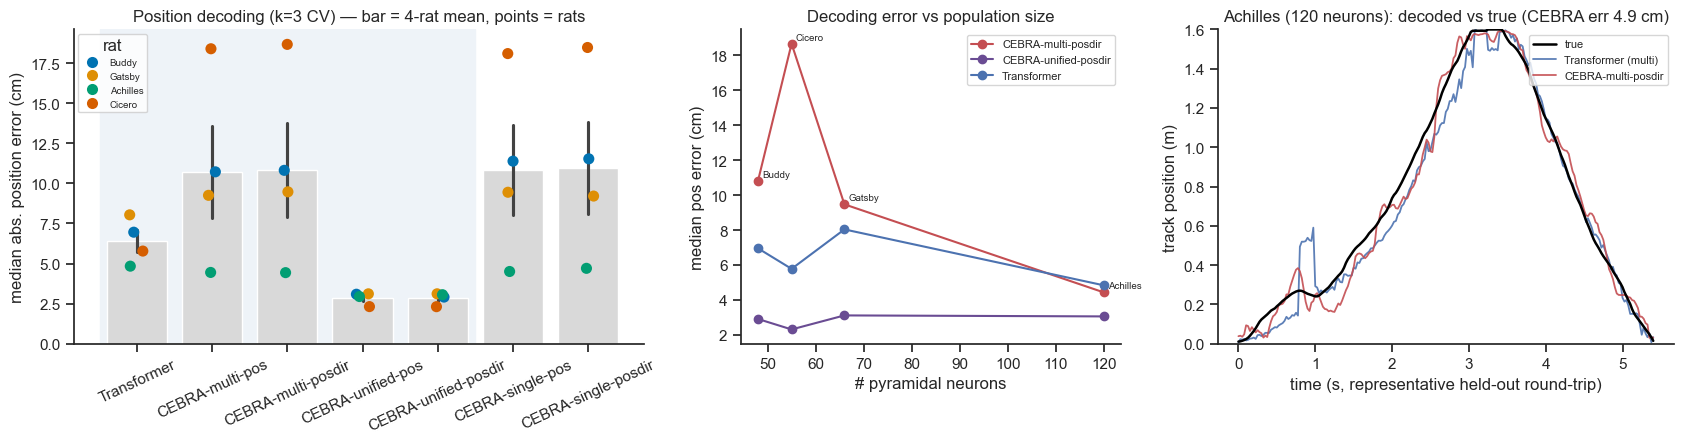

model,CEBRA-multi-pos,CEBRA-multi-posdir,CEBRA-single-pos,CEBRA-single-posdir,CEBRA-unified-pos,CEBRA-unified-posdir,Transformer
session,,,,,,,
Achilles_10252013,4.4,4.4,4.5,4.7,2.9,3.1,4.8
Buddy_06272013,10.7,10.8,11.4,11.5,3.1,2.9,7.0
Cicero_09012014,18.4,18.7,18.1,18.5,2.3,2.3,5.8
Gatsby_08022013,9.3,9.5,9.4,9.2,3.1,3.1,8.0


In [63]:
# Comparison: main = multisession Transformer vs multisession CEBRA; single-session CEBRA for reference.
# Bars = 4-rat mean; points = individual rats. Decoding error scales with population size, so the
# small-population rats (Buddy 48, Gatsby 66 neurons) drag the mean up while Achilles (120) ~ the paper.
MODEL_ORDER = ['Transformer', 'CEBRA-multi-pos', 'CEBRA-multi-posdir', 'CEBRA-unified-pos',
               'CEBRA-unified-posdir', 'CEBRA-single-pos', 'CEBRA-single-posdir']
model_pal = {'Transformer': '#4c72b0', 'CEBRA-multi-pos': '#dd8452', 'CEBRA-multi-posdir': '#c44e52',
             'CEBRA-unified-pos': '#8172b3', 'CEBRA-unified-posdir': '#6a4c93',
             'CEBRA-single-pos': '#c8b9a6', 'CEBRA-single-posdir': '#a89078'}
decode_summary['n_pyr'] = decode_summary.session.map(lambda s: SESS[s]['K'])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw={'width_ratios': [1.5, 1, 1.2]})

# (0) position error: bar = 4-rat mean, points coloured by rat
ax = axes[0]
sns.barplot(data=decode_summary, x='model', y='pos_err_cm', order=MODEL_ORDER, color='0.85',
            errorbar='se', ax=ax)
sns.stripplot(data=decode_summary, x='model', y='pos_err_cm', order=MODEL_ORDER, hue='rat',
              palette=rat_palette, size=8, ax=ax)
ax.axvspan(-0.5, 4.5, color='#eef3f8', zorder=0)             # shade the shared-model (multi + unified) comparison
ax.set(xlabel='', ylabel='median abs. position error (cm)',
       title='Position decoding (k=3 CV) — bar = 4-rat mean, points = rats')
ax.tick_params(axis='x', rotation=25); ax.legend(title='rat', fontsize=7, loc='upper left')
sns.despine(ax=ax)

# (1) why the mean is high: error vs population size, per rat
ax = axes[1]
for model in ['CEBRA-multi-posdir', 'CEBRA-unified-posdir', 'Transformer']:
    sub = decode_summary[decode_summary.model == model].sort_values('n_pyr')
    ax.plot(sub.n_pyr, sub.pos_err_cm, 'o-', color=model_pal[model], label=model)
for _, r in decode_summary[decode_summary.model == 'CEBRA-multi-posdir'].iterrows():
    ax.annotate(r['rat'], (r['n_pyr'], r['pos_err_cm']), fontsize=7, xytext=(3, 3), textcoords='offset points')
ax.set(xlabel='# pyramidal neurons', ylabel='median pos error (cm)', title='Decoding error vs population size')
ax.legend(fontsize=8); sns.despine(ax=ax)

# (2) example decoded vs true over a representative held-out round-trip (Fig 2d left)
ax = axes[2]
tt = np.arange(len(example['true'])) * NEUR_BIN
ax.plot(tt, example['true'], color='k', lw=1.8, label='true', zorder=3)
ax.plot(tt, example['t_pred'], color=model_pal['Transformer'], lw=1.3, alpha=0.9, label='Transformer (multi)')
ax.plot(tt, example['c_pred'], color=model_pal['CEBRA-multi-posdir'], lw=1.3, alpha=0.9, label='CEBRA-multi-posdir')
ax.set(xlabel='time (s, representative held-out round-trip)', ylabel='track position (m)',
       title=f'{ANIMAL[PRIMARY]} ({SESS[PRIMARY]["K"]} neurons): decoded vs true '
             f'(CEBRA err {example["err_cm"]:.1f} cm)', ylim=(0, 1.6))
ax.legend(fontsize=8, loc='upper right'); sns.despine(ax=ax)
fig.tight_layout()
plt.show()

# per-rat table (median pos error in cm), so Achilles is visible alongside the rat-averaged bars
decode_summary.pivot(index='session', columns='model', values='pos_err_cm').round(1)

### Side-by-side latent spaces: CEBRA vs Transformer

The two decoders also yield comparable **latent spaces**. We embed the primary rat's running bins with
the **multisession CEBRA-posdir** model (3-D) and with the **multisession Transformer**'s internal
representation — the RoPE-encoder output just before the position read-out, extracted per one-way
traversal and reduced to 3-D with PCA. Both are coloured by position and by direction (Fig 1d / 2b
style). A clean position "loop" with direction-split structure in both indicates each model has
recovered the track topology.

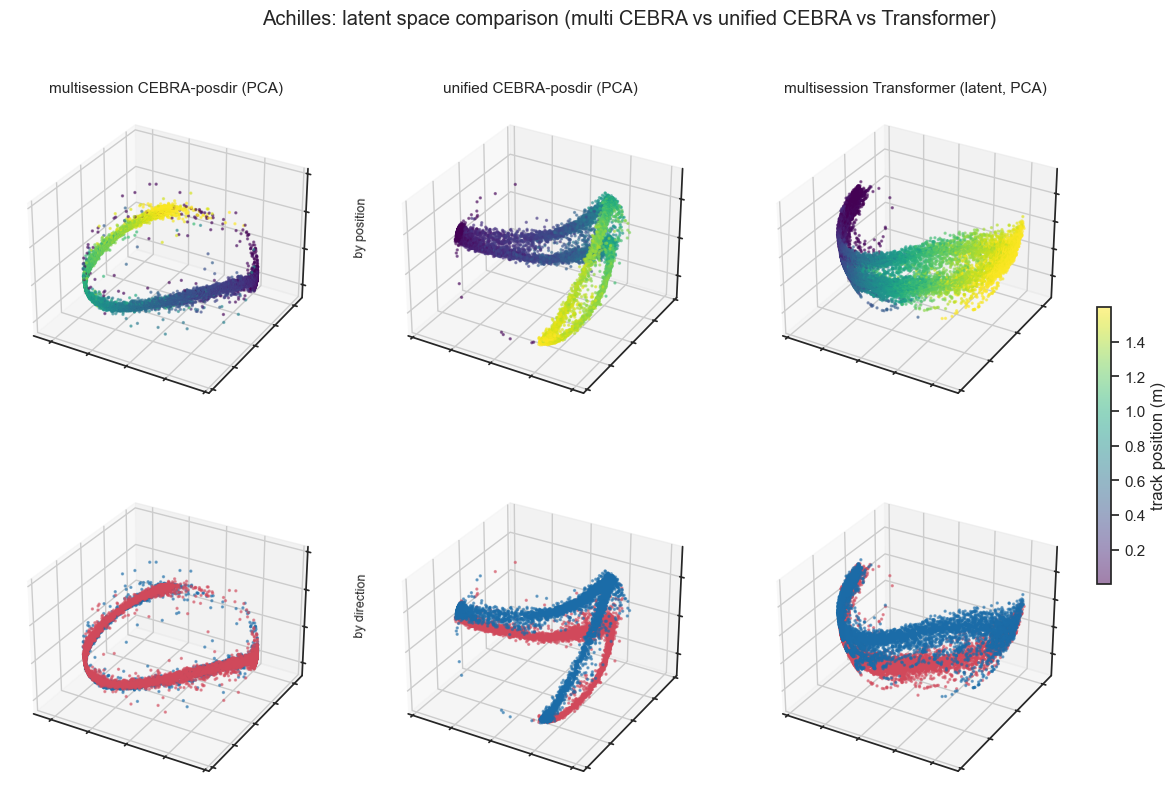

In [64]:
from sklearn.decomposition import PCA as _PCA


# Primary rat: same running bins (one-way traversals, all folds) for all models
_ow = [o['idx'] for o in SESS[PRIMARY]['oneway']]
_ow_idx = np.concatenate(_ow)
_pos = SESS[PRIMARY]['pos'][_ow_idx]
_dir = SESS[PRIMARY]['direction'][_ow_idx]

# multisession CEBRA-posdir (round-0) and Transformer latent (round-0), each PCA->3D
E_cebra = _PCA(n_components=3).fit_transform(multi0.transform(SESS[PRIMARY]['neural'][_ow_idx], session_id=i_pr))
E_trans = _PCA(n_components=3).fit_transform(np.vstack([transformer_latent(model0, PRIMARY, ix) for ix in _ow]))

# Unified CEBRA-posdir (round-0): the shared model needs ALL rats' streams+labels at inference; we put
# PRIMARY's one-way bins in its slot and the other rats' trainval streams in theirs, then read rat i_pr.
_Xs_v = [SESS[PRIMARY]['neural'][_ow_idx] if s == PRIMARY else _uXtv0[k] for k, s in enumerate(SESSIONS)]
_Ys_v = [cebra_label('posdir', _pos, _dir) if s == PRIMARY else _uYtv0[k] for k, s in enumerate(SESSIONS)]
E_unified = _PCA(n_components=3).fit_transform(unified_transform(unified0, _Xs_v, _Ys_v, i_pr))

latent_panels = [('multisession CEBRA-posdir (PCA)', E_cebra),
                 ('unified CEBRA-posdir (PCA)', E_unified),
                 ('multisession Transformer (latent, PCA)', E_trans)]
ncols = len(latent_panels)
fig = plt.figure(figsize=(5.5 * ncols, 9))
for col, (title, E) in enumerate(latent_panels):
    axp = fig.add_subplot(2, ncols, col + 1, projection='3d')
    sc = axp.scatter(E[:, 0], E[:, 1], E[:, 2], c=_pos, cmap='viridis', s=2, alpha=0.5)
    axp.set_title(title, fontsize=11)
    if col == 0:
        axp.set_zlabel('by position', fontsize=9)
    axd = fig.add_subplot(2, ncols, ncols + col + 1, projection='3d')
    for dv, c in [(1, dir_palette['rightward (0→1.6)']), (0, dir_palette['leftward (1.6→0)'])]:
        m = _dir == dv
        axd.scatter(E[m, 0], E[m, 1], E[m, 2], c=c, s=2, alpha=0.5)
    if col == 0:
        axd.set_zlabel('by direction', fontsize=9)
    for a in (axp, axd):
        a.set_xticklabels([]); a.set_yticklabels([]); a.set_zticklabels([])
fig.colorbar(sc, ax=fig.axes, shrink=0.4, pad=0.02, label='track position (m)', location='right')
fig.suptitle(f'{ANIMAL[PRIMARY]}: latent space comparison (multi CEBRA vs unified CEBRA vs Transformer)', y=0.98)
plt.show()

## 8. Topological data analysis (Fig 2e–g)

Following the CEBRA paper / `Demo_cohomology`: CEBRA-Behaviour (posdir) is trained on the **full**
single-session data at latent dim **3** (the two-sphere; `temperature 1, time_offset 10, batch 512,
10,000 steps`); we take **1,000 random points** (seed 111) and compute persistent cohomology with
**ripser** up to **H2** (coeff 47). Significant cocycles are those whose lifespan exceeds **1.1 × the
maximum lifespan over the shuffled-label null** (the paper's method).

**Speed note:** `ripser` at maxdim=2 on 1,000 points is ~80 s *each*, so a full 500-shuffle ×
multi-dim null is multi-day (the demo ships precomputed H2 results for this reason). Since β2=0 is
robust (null-H2 ≫ real-H2), we use a **hybrid null** — `TDA_N_SHUFFLE`=200 shuffles at maxdim=1 for
the H0/H1 thresholds (fast) plus `TDA_N_SHUFFLE_H2`=20 at maxdim=2 for the H2 threshold — and report
the **headline dim-3 two-sphere** (set `TDA_DIMS=[3,8,16,32,64]` to survey more, much slower). The
null is **cached** (`tmp/build_tda_null.py` precomputes it in the background; the cell then loads it).
For a linear track the result is the **ring**: Betti **(1, 1, 0)**. The circular-coordinate panel
(Fig 2g) uses a PCA ring-phase proxy because **DREiMac is not installed**.

dim  3: Betti = (1, 1, 0)   threshold(x1.1) = [0.72  0.549 0.989]


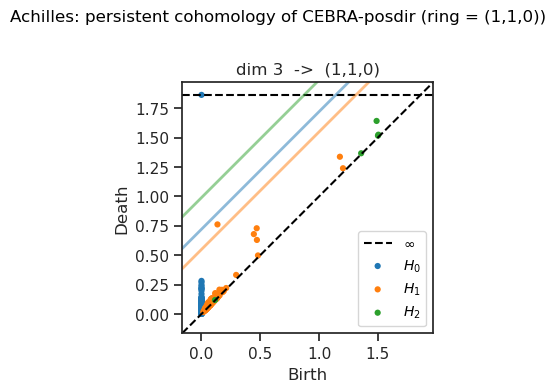

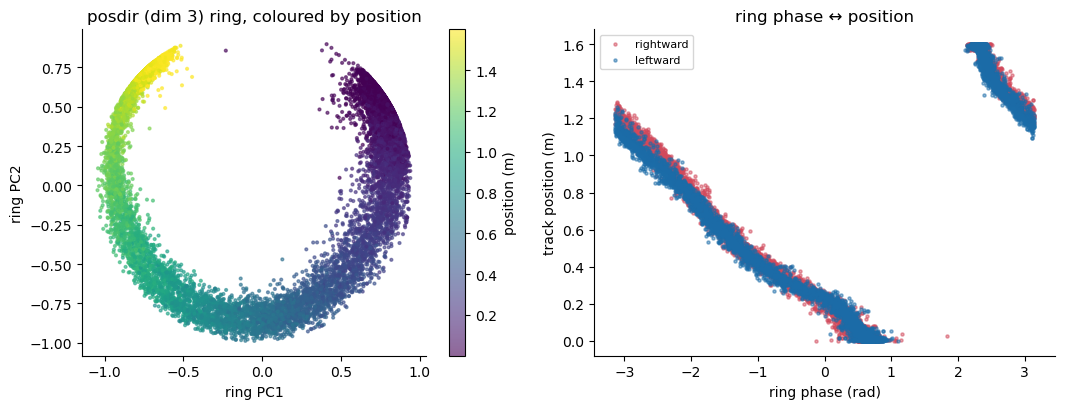

In [65]:
from ripser import ripser
from persim import plot_diagrams
from sklearn.decomposition import PCA

# Topological data analysis following the CEBRA paper / Demo_cohomology:
#  - CEBRA-Behaviour (posdir) on the FULL single-session data, latent dims 3,8,16,32,64, 10k steps
#  - 1,000 random points, ripser up to H2 (coeff 47)
#  - significance threshold = max lifespan over TDA_N_SHUFFLE shuffled-LABEL retrains, x1.1
dprim = SESS[PRIMARY]
_all = np.concatenate(dprim['trials'])
_Xfull = dprim['neural'][_all]
_pos, _dir = dprim['pos'][_all], dprim['direction'][_all]
_Yfull = cebra_label('posdir', _pos, _dir)
_ridx = np.random.RandomState(TDA_SEED).permutation(len(_Xfull))[:TDA_NPOINTS]


def _posdir_embedding(dim, max_iter, shuffle_seed=None):
    """Full-data posdir embedding; real (shuffle_seed=None, cached) or shuffled-label null."""
    if shuffle_seed is None:
        m = cebra_cached(f'tda_real_{PRIMARY}_d{dim}_it{max_iter}',
                         lambda: fit_cebra_xy(_Xfull, _Yfull, 'posdir', dim=dim, seed=0, max_iter=max_iter))
        return m.transform(_Xfull)
    y = np.random.RandomState(shuffle_seed).permutation(_Yfull)              # shuffled label
    m = fit_cebra_xy(_Xfull, y, 'posdir', dim=dim, seed=shuffle_seed, max_iter=max_iter)  # not cached
    return m.transform(_Xfull)


def _dgms(E):
    return ripser(E[_ridx], maxdim=TDA_MAXDIM, coeff=TDA_COEFF)['dgms']


def _max_lifespans(dgms):
    out = []
    for d in range(TDA_MAXDIM + 1):
        ls = dgms[d][:, 1] - dgms[d][:, 0]
        ls = ls[np.isfinite(ls)]
        out.append(float(ls.max()) if len(ls) else 0.0)
    return out


def _null_max_lifespan(dim):
    """Hybrid shuffled-LABEL null: TDA_N_SHUFFLE models give H0/H1 lifespans (maxdim=1, fast);
    the first TDA_N_SHUFFLE_H2 of them also run maxdim=2 for the (robust, beta2=0) H2 threshold."""
    path = cache_path(f'tda_nullmax_{PRIMARY}_d{dim}_n{TDA_N_SHUFFLE}h2{TDA_N_SHUFFLE_H2}_it{TDA_NULL_STEPS}.json')
    if (not FORCE_RETRAIN) and os.path.exists(path):
        return json.load(open(path))
    acc = [0.0] * (TDA_MAXDIM + 1)
    for sidx in range(TDA_N_SHUFFLE):
        E = _posdir_embedding(dim, TDA_NULL_STEPS, shuffle_seed=1000 + sidx)
        md = TDA_MAXDIM if sidx < TDA_N_SHUFFLE_H2 else 1
        dgms = ripser(E[_ridx], maxdim=md, coeff=TDA_COEFF)['dgms']
        for k in range(md + 1):
            ls = dgms[k][:, 1] - dgms[k][:, 0]; ls = ls[np.isfinite(ls)]
            if len(ls):
                acc[k] = max(acc[k], float(ls.max()))
    json.dump(acc, open(path, 'w'))
    return acc


def betti_from_null(dgms, null_max):
    thr = [m * TDA_MARGIN for m in null_max]
    return [int(((dgms[d][:, 1] - dgms[d][:, 0]) > thr[d]).sum()) for d in range(TDA_MAXDIM + 1)], thr


# Real embeddings + Betti per latent dim (null is cached; first run is long -- see tmp/build_tda_null.py)
tda = {}
for dim in TDA_DIMS:
    real_dgms = _dgms(_posdir_embedding(dim, TDA_STEPS))
    null_max = _null_max_lifespan(dim)
    betti, thr = betti_from_null(real_dgms, null_max)
    tda[dim] = dict(dgms=real_dgms, thr=thr, betti=betti)
    print(f'dim {dim:2d}: Betti = ({betti[0]}, {betti[1]}, {betti[2]})   threshold(x1.1) = {np.round(thr, 3)}')

# Lifespan diagrams with per-dimension significance thresholds (Demo_cohomology style)
hom_lbl = ['H0', 'H1', 'H2']
fig, axes = plt.subplots(1, len(TDA_DIMS), figsize=(4 * len(TDA_DIMS), 3.8))
for ax, dim in zip(np.atleast_1d(axes), TDA_DIMS):
    d = tda[dim]
    plot_diagrams(d['dgms'], ax=ax, legend=(dim == TDA_DIMS[0]))
    for k, col in enumerate(['C0', 'C1', 'C2'][:TDA_MAXDIM + 1]):
        ax.plot([-0.3, 2], [-0.3 + d['thr'][k], 2 + d['thr'][k]], color=col, lw=2, alpha=0.5)
    ax.set_title(f"dim {dim}  ->  ({d['betti'][0]},{d['betti'][1]},{d['betti'][2]})")
fig.suptitle(f'{ANIMAL[PRIMARY]}: persistent cohomology of CEBRA-posdir (ring = (1,1,0))', y=1.02)
fig.tight_layout()
plt.show()

# Ring phase (principal-plane angle) vs track position (Fig 2g; DREiMac not installed -> PCA-angle proxy)
E3 = _posdir_embedding(3, TDA_STEPS)
ring = PCA(n_components=2).fit_transform(E3 - E3.mean(0))
phase = np.arctan2(ring[:, 1], ring[:, 0])
fig, (a0, a1) = plt.subplots(1, 2, figsize=(11, 4.2))
sc = a0.scatter(ring[:, 0], ring[:, 1], c=_pos, cmap='viridis', s=4, alpha=0.6)
a0.set(xlabel='ring PC1', ylabel='ring PC2', title='posdir (dim 3) ring, coloured by position')
fig.colorbar(sc, ax=a0, label='position (m)'); a0.set_aspect('equal'); sns.despine(ax=a0)
for dv, c in [(1, dir_palette['rightward (0→1.6)']), (0, dir_palette['leftward (1.6→0)'])]:
    m = _dir == dv
    a1.scatter(phase[m], _pos[m], s=5, color=c, alpha=0.5, label='rightward' if dv else 'leftward')
a1.set(xlabel='ring phase (rad)', ylabel='track position (m)', title='ring phase ↔ position')
a1.legend(fontsize=8); sns.despine(ax=a1)
fig.tight_layout()
plt.show()